# Pipeline review — field 860

A row is a ZTF deep-reference object with its PS1 DR2 stack match at 1″, or an unmatched PS1 object; bands g, r, i.
Sections follow the pipeline (README, "The filtering pipeline at a glance"): **1 inputs** → per band, every object:
**2 quality** (each survey's side usable, or X) → **3 detection** (D / L / U) → **4 comparison and sorting** (≥ 2
comparable bands of one kind → `in_both` / `in_ztf` / `in_pstarr`, else not comparable) → per catalog, object-wide:
**5 confident** → **6 population** → **7 calibrate** (recovery limits; one Δmag envelope per morphology, on what is left) → **8 interesting**
→ **9 results**. A dropped band stays dropped; an object leaves as soon as fewer than two bands remain.
The pipeline runs in memory below (`ff.prepare_field` on the field's `merged.parquet`, then `ff.filter_prepared`, ~2 min).
The field table must come from the current builder (it carries the ZTF depth columns `{b}_ztf_mag_5sigma`, `{b}_ztf_gpctsig`,
`{b}_ztf_medpunc` and the PS1 columns `{b}_ps1_psfChiSq`, `ps1_n_primary_rows`), and `Data/ps1/stack_deteff_gri.parquet`
(`ps1_stack.fetch_stack_deteff`) must exist for the PS1 limits.
Code: `Source_Analysis/filter_field.py`; columns: `docs/object_columns.md`. Figures go to `Data/fields/000860/review/`.

In [ ]:
import os, sys, io, warnings; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from collections import OrderedDict
from IPython.display import display
from scipy.stats import norm
from scipy.spatial import cKDTree
from astropy.nddata import Cutout2D
from astropy.coordinates import SkyCoord, match_coordinates_sky
from astropy.visualization import simple_norm
import astropy.units as u
from matplotlib.lines import Line2D
from Extracting.images import load_refimg
from Extracting.ztf_products import refimg_path
from Extracting import ps1_skycells, ps1_stack
from Source_Analysis import filter_field as ff
from source_db.cutouts.render import DEFAULT_STRETCH, DEFAULT_PERCENT
warnings.filterwarnings('ignore')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
FIELD, D = 860, '../Data'
CUTS = ff.Cuts()
print(CUTS)
base = ff.prepare_field(FIELD, D)
src, env, cands, wfs = ff.filter_prepared(base, CUTS, verbose=False)
del base
CAT = {name: k for k, name in ff.CATALOG.items()}
NAMES = list(CAT)

Cuts(bright_star_mask=True, sharp_max=0.5, sharp_point_only=True, ps1_sky_max=1e-07, ps1_min_nframes=4, isolation_arcsec=3.0, neighbour_kron=True, snr_keep=None, envelope_clip_mad=5.0)


## 1. Inputs

Builder (`Extracting.field_tables.build_field`; writes `ztf_{b}`, `ztf`, `ps1`, `merged` parquet files):
- `merge_bands` — ZTF g, r, i detections linked into objects (mutual nearest at 1″), S/N-weighted position.
- `ztf_coverage` — per band, the ZTF image covering a position (`{b}_ccd`/`{b}_qid`, covered, px to a mask) and its depth
  (`{b}_ztf_maglim_header`, `{b}_ztf_mag_5sigma`, `{b}_ztf_gpctsig`, `{b}_ztf_medpunc`: header MAGLIM, the catalog's 5σ depth, the image's pixel scatter and the modelled one).
- `ps1_neighbourhood` — `{b}_ps1_covered` (a PS1 object measured in b within 1′) and `{b}_ps1_nframes_local`.
- `match_ps1` — ZTF objects to PS1 objects, mutual nearest within 1″.
- `merge_tables` — every ZTF object with its match, then every unmatched PS1 object: `merged.parquet`.

Filter preparation (`ff.prepare_field`):
- `ff.load_merged` — reads `merged.parquet`; 0.01 mag error floor; `{b}_ps1_meas`, `{b}_ps1_snr`.
- `ff.annotate_skycells` — `ps1_catalog_missing` (no PS1 object in a DR2 missing-data box or Dec < −30).
- `ff.annotate_bright_stars` — `bright_star_d_over_R`, `in_star_spike` (Gaia G < 16 mask circles and spike boxes; the boxes lie along the
  detector columns, whose position angle `ff.ztf_column_pa` reads off each quadrant's WCS: ±17° over this field).
- `ff.annotate_gaia` — nearest Gaia DR3 source within 5″: `gaia_pm`, `gaia_pmra`/`gaia_pmdec` and errors, `gaia_parallax_over_error`.
- `ff.annotate_neighbours` — `inside_brighter_kron` (`nearest_other_arcsec` comes from the builder). The Kron-containment check that
  reads it is off (`Cuts.neighbour_kron = False`: over-strict for hosted sources).

In [ ]:
n = {'ZTF objects': int((src.ztf_idx >= 0).sum()), 'PS1 objects': int((src.ps1_idx >= 0).sum()), 'matched at 1″': int(((src.ztf_idx >= 0) & (src.ps1_idx >= 0)).sum())}
for b in 'gri':
    n[f'ZTF {b} detections'] = int(ff.ztf_detected(src, b).sum()); n[f'PS1 {b} detections'] = int(src[f'{b}_ps1_detected'].sum())
display(pd.Series(n, name='count').to_frame().T)

,ZTF objects,PS1 objects,matched at 1″,ZTF g detections,PS1 g detections,ZTF r detections,PS1 r detections,ZTF i detections,PS1 i detections
count,6230854,2296477,1332799,2387795,878518,3231242,971621,2940043,1388896


## How to read the filter tables, flowcharts and cutouts

Quality (section 2) is judged per survey and per band, each band on its own over every object (`ff.quality_table`,
`ff.quality_flowchart`). Band combinations first appear at the sort (section 4, `ff.sort_table`). After the sort each
catalog runs its object-wide checks (`ff.catalog_checks`: confident, population, interesting; `ff.catalog_table`,
`ff.catalog_flowchart`).

Tables (`ff.check_table`), one row per check in pipeline order, over the start (every object for quality; the objects
sorted into the catalog after the sort):

| column | meaning |
|---|---|
| **after** | objects passing this check and every earlier one |
| **total fail**, **total fail %** | objects failing this check, whatever the others say; % of the start |
| **unique**, **unique %** | objects failing this check and no other: what only this check catches; % of the start |

A `–` means the check is not part of that catalog's chain. Flowcharts show **Pass** (= after) and **Fraction** (of the start).

Cutouts (saved under `Data/fields/000860/review/filter_cutouts/<group>/<catalog>.png`, too large to show inline):
random objects a check removes from its chain (passing every earlier check, failing this one) — ZTF reference (the
band's own quadrant, `{b}_ccd`/`{b}_qid`) over PS1 stack in the band the check cuts, 30″, north up; red + the object,
white ○ ZTF objects, orange □ PS1 objects; magnitudes in red, the object's catalog top left, a red ★ if the check
removes it uniquely.

In [ ]:
# ---- the check tables (ff.check_table): after, total fail, unique, with % of the start
QT = {sv: ff.quality_table(src, sv, CUTS) for sv in ff.SURVEY_CHECKS}
CT = ff.catalog_table(src, CUTS)
GROUP_CHECKS = {'confident': lambda k: ff.real_checks(src, k, CUTS), 'population': lambda k: ff.population_checks(src),
                'interesting': lambda k: ff.interesting_checks(src)}
CHAIN_ORDER = ['in_pstarr', 'in_ztf', 'in_both']                    # in_pstarr runs every confident check: its order is the chain's

def pretty(t):
    out = t.astype(object).copy()
    for col in t.columns:
        key = col[-1] if isinstance(col, tuple) else col
        f = (lambda v: f'{v:.2f}') if key.endswith('%') else (lambda v: f'{int(v):,}')
        out[col] = t[col].map(lambda v: '–' if pd.isna(v) else f(v))
    return out

def quality_block(survey):
    """one survey's quality checks, g, r, i side by side, each over every object"""
    t = QT[survey]
    return pretty(pd.concat({f'{b} (start {len(src):,})': t.loc[b] for b in 'gri'}, axis=1))

def catalog_block(group):
    """one group's checks after the sort, one block per catalog over the objects sorted into it"""
    labels = list(dict.fromkeys(l for name in CHAIN_ORDER for l, _ in GROUP_CHECKS[group](CAT[name])))
    n0 = {name: int((src.catalog.values == CAT[name]).sum()) for name in NAMES}
    return pretty(pd.concat({f'{name} (start {n0[name]:,})': CT.loc[name].reindex(labels) for name in NAMES}, axis=1))

def chain_masks(checks, start):
    """per check, as in ff.check_table: (removed in the chain: passing every earlier check and failing this one,
    unique: failing this check and no other)"""
    fails = [start & ~np.asarray(ok, bool) for _, ok in checks]
    n_fail = sum(f.astype(np.int8) for f in fails)
    alive, out = start.copy(), {}
    for (l, ok), f in zip(checks, fails):
        out[l] = (alive & ~ok, f & (n_fail == 1)); alive = alive & ok
    return out

# ---- cutouts: ZTF reference over PS1 stack, in the band the step cuts
from astropy.io import fits
from astropy.wcs import WCS
from source_db.cutouts.render import ps1_cutout_url, ps1_linear_flux, _get_fits
from source_db.cutouts.panstarrs import _post as ps1_filenames
REVIEW_DIR = f'{D}/fields/{FIELD:06d}/review'; PS1_CACHE = f'{REVIEW_DIR}/ps1_stamps'; os.makedirs(PS1_CACHE, exist_ok=True)
_refs = OrderedDict()
def ref_image(ccd, qid, b='r'):
    key = (ccd, qid, b)
    if key not in _refs:
        if len(_refs) >= 12: _refs.popitem(last=False)
        _refs[key] = load_refimg(refimg_path(f'{D}/ztf_data', FIELD, *key))
    return _refs[key]
cosd = np.cos(np.radians(src.dec.median()))
objs = {'ZTF': src[src.ztf_idx >= 0], 'PS1': src[src.ps1_idx >= 0]}
trees = {k: cKDTree(np.c_[v.ra.values * cosd, v.dec.values]) for k, v in objs.items()}

def ps1_stamp(r, b, files, size):
    path = os.path.join(PS1_CACHE, f'{r.ra:.6f}_{r.dec:+.6f}_{b}_{size}.fits')
    if not os.path.exists(path):
        name = files.get((round(r.ra, 6), round(r.dec, 6), b))
        raw = _get_fits(ps1_cutout_url(r.ra, r.dec, name, int(size / 0.25))) if name else None
        if not raw: return None, None
        open(path, 'wb').write(raw)
    hdu = fits.open(path)[0]
    return ps1_linear_flux(hdu.data.astype(np.float32), hdu.header), WCS(hdu.header)

def draw(ax, data, wcs, r, b, survey, size, star=False):
    ax.set_xticks([]); ax.set_yticks([])
    if data is None or data.size == 0 or not np.isfinite(data).any():
        ax.text(0.5, 0.5, 'no image', ha='center', va='center', transform=ax.transAxes); return
    flip = wcs.pixel_scale_matrix[0, 0] > 0
    data = data[::-1, ::-1] if flip else data
    def pix(ra, dec):
        x, y = wcs.world_to_pixel_values(np.asarray(ra), np.asarray(dec))
        return (data.shape[1] - 1 - x, data.shape[0] - 1 - y) if flip else (x, y)
    ax.imshow(data, origin='lower', cmap='viridis', norm=simple_norm(data, DEFAULT_STRETCH, percent=DEFAULT_PERCENT))
    for (k, o), (col, mk, s) in zip(objs.items(), (('white', 'o', 90), ('orange', 's', 50))):
        hit = o.iloc[trees[k].query_ball_point([r.ra * cosd, r.dec], size * 0.75 / 3600)]
        x, y = pix(hit.ra.values, hit.dec.values); ax.scatter(x, y, s=s, marker=mk, facecolors='none', edgecolors=col, lw=1.1)
    x, y = pix([r.ra], [r.dec]); ax.plot(x, y, '+', color='red', ms=14, mew=1.6)
    ax.set_xlim(-0.5, data.shape[1] - 0.5); ax.set_ylim(-0.5, data.shape[0] - 0.5)
    m = r[f'{b}_ztf_psf'] if survey == 'ZTF' else r[f'{b}_ps1_psf']
    ax.text(0.97, 0.97, f'{survey} {b} ' + (f'{m:.1f}' if np.isfinite(m) else '–'), color='red', fontsize=8, ha='right', va='top', transform=ax.transAxes)
    if star: ax.text(0.97, 0.03, '★', color='red', fontsize=22, ha='right', va='bottom', transform=ax.transAxes)

from astropy.nddata import NoOverlapError
def stamp_pair(ax_z, ax_p, r, b, files, size=30, star=False):
    try:
        im = ref_image(int(r[f'{b}_ccd']), int(r[f'{b}_qid']), b)
        cut = Cutout2D(im.data, SkyCoord(r.ra * u.deg, r.dec * u.deg), size * u.arcsec, wcs=im.wcs, mode='partial')
        draw(ax_z, cut.data, cut.wcs, r, b, 'ZTF', size, star)
    except (NoOverlapError, FileNotFoundError, ValueError):                 # off the ZTF image (e.g. "ZTF image covers the position")
        draw(ax_z, None, None, r, b, 'ZTF', size, star)
    draw(ax_p, *ps1_stamp(r, b, files, size), r, b, 'PS1', size, star)
    ax_p.set_xlabel(f'{r.ra:.4f} {r.dec:+.4f}   ' + '/'.join(f"{r[f'{x}_ztf_status']}{r[f'{x}_ps1_status']}" for x in 'gri') + f'   cut: {b}', fontsize=7)

# the catalog an object would belong to before any quality check: where its S/N >= 5 measurements are, trusted or not
_z = np.logical_or.reduce([ff.ztf_detected(src, b) & (src[f'{b}_ztf_snr'].values >= ff.SNR_MIN) for b in 'gri'])
_p = np.logical_or.reduce([src[f'{b}_ps1_meas'].values & (src[f'{b}_ps1_snr'].values >= ff.SNR_MIN) for b in 'gri'])
pre_catalog = np.select([_z & _p, _z, _p], ['in_both', 'in_ztf', 'in_pstarr'], 'neither')


def plot_steps(steps, group, name, sigma=False, n=6, size=30):
    """one ZTF row over one PS1 row per check: `steps` is [(label, n removed, rows)], rows with the src row, the band
    to show, whether the check removes it uniquely, and its catalog"""
    K = len(steps)
    if K == 0:
        print(f'{group}: no checks'); return
    fig, axes = plt.subplots(3 * K - 1, n, figsize=(2.6 * n, 2.9 * 2 * K + 0.6 * (K - 1)), squeeze=False,
                             gridspec_kw={'height_ratios': [v for k in range(K) for v in ([1, 1, 0.2] if k < K - 1 else [1, 1])]})
    for k, (l, n_rem, rows) in enumerate(steps):
        ax_z, ax_p = axes[3 * k], axes[3 * k + 1]
        if k < K - 1:
            for ax in axes[3 * k + 2]: ax.axis('off')
        files = ps1_filenames(rows[['ra', 'dec']]).round({'ra': 6, 'dec': 6}).groupby(['ra', 'dec', 'filter']).filename.first() if len(rows) else {}
        for j, (_, r) in enumerate(rows.iterrows()):
            stamp_pair(ax_z[j], ax_p[j], r, r.show_band, files, size, star=bool(r.uniquely_removed))
            ax_z[j].text(0.03, 0.97, r.catalog_name + ('\nσ ' + ' '.join(f"{x}{r[f'{x}_sigma']:+.1f}" for x in 'gri' if np.isfinite(r[f'{x}_sigma'])) if sigma else ''),
                         color='red', fontsize=7, ha='left', va='top', transform=ax_z[j].transAxes)
        for j in range(len(rows), n): ax_z[j].axis('off'); ax_p[j].axis('off')
        ax_z[0].set_ylabel(f'{l}\n(removes {n_rem:,})\nZTF', fontsize=8); ax_p[0].set_ylabel('PS1', fontsize=8)
        if len(rows) == 0:
            ax_z[0].axis('on'); ax_z[0].set_xticks([]); ax_z[0].set_yticks([])
            ax_z[0].text(0.5, 0.5, f'"{l}"\nremoves nothing in the chain', transform=ax_z[0].transAxes, ha='center', va='center', fontsize=9)
    plt.tight_layout()
    os.makedirs(f'{REVIEW_DIR}/filter_cutouts/{group}', exist_ok=True)
    out = f'{REVIEW_DIR}/filter_cutouts/{group}/{name}.png'
    fig.savefig(out, dpi=80); plt.close(fig)                              # too large to view inline: saved, not shown
    print(f'saved {K} checks → {os.path.abspath(out)}')

def sample_rows(idx, band, unique, catalog_name, n, rng):
    """`n` random rows of `idx` as src rows with their band, unique flag and catalog"""
    pick = rng.choice(len(idx), min(n, len(idx)), replace=False) if len(idx) else np.array([], int)
    rows = src.iloc[idx[pick]].assign(show_band=np.asarray(band)[pick], uniquely_removed=np.asarray(unique)[pick],
                                      catalog_name=np.asarray(catalog_name)[pick])
    return rows.sort_values(['r_ccd', 'r_qid'])

def cutouts_quality(survey, catalog=None, n=6, seed=0, size=30):
    """random objects each of `survey`'s quality checks removes from a band's chain, shown in that band (r first if
    several); with `catalog`, objects whose S/N >= 5 measurements would put them in it (`pre_catalog`)"""
    rng = np.random.default_rng(seed)
    pool = np.ones(len(src), bool) if catalog is None else pre_catalog == catalog
    hits = {}                                                              # check -> [(rows, band, unique)]
    for b in 'rgi':
        for l, (rem, uniq) in chain_masks(ff.SURVEY_CHECKS[survey](src, b, CUTS), np.ones(len(src), bool)).items():
            idx = np.flatnonzero(rem & pool)
            hits.setdefault(l, []).append(pd.DataFrame({'row': idx, 'band': b, 'unique': uniq[idx]}))
    steps = []
    for l, parts in hits.items():
        t = pd.concat(parts).drop_duplicates('row')                        # an object once, in its first band of r, g, i
        steps.append((l, len(t), sample_rows(t.row.values, t.band.values, t.unique.values, pre_catalog[t.row.values], n, rng)))
    plot_steps(steps, f'quality_{survey}', catalog or 'all', n=n, size=size)

def cutouts_catalog(group, catalog, n=6, seed=0, size=30):
    """random objects each of the group's checks removes from `catalog`'s chain (`ff.catalog_checks`), shown in r if
    measured (σ checks: the compared band with the largest |σ|)"""
    rng = np.random.default_rng(seed)
    k = CAT[catalog]
    masks = chain_masks(ff.catalog_checks(src, k, CUTS), src.catalog.values == k)
    sig = np.column_stack([np.where(src[f'{b}_cat'].values >= 0, np.abs(src[f'{b}_sigma'].values), -1) for b in 'gri'])
    sig = np.nan_to_num(sig, nan=-1)
    measured = np.column_stack([ff.ztf_detected(src, b) | src[f'{b}_ps1_meas'].values for b in 'gri'])
    steps = []
    for l, _ in GROUP_CHECKS[group](k):
        rem, uniq = masks[l]
        idx = np.flatnonzero(rem)
        if group == 'interesting':
            band = np.array(list('gri'))[sig[idx].argmax(axis=1)]
        else:
            band = np.where(measured[idx, 1], 'r', np.array(list('gri'))[measured[idx].argmax(axis=1)])
        steps.append((l, len(idx), sample_rows(idx, band, uniq[idx], np.full(len(idx), catalog), n, rng)))
    plot_steps(steps, group, catalog, sigma=group == 'interesting', n=n, size=size)

## 2. Quality (per band, per survey: usable or X)

- `ff.usable_sides` — a side passing all its checks is usable, else **X**: nothing on it, measurement or limit, is compared.
- `ff.ztf_checks` — ZTF's side, in order below (uses `ff.ztf_detected`, `ff.bright_star_masked`).
- `ff.ps1_checks` — PS1's side, in order below (uses `ff.ps1_skycell_bad`, `ps1_catalog_missing`, `{b}_ps1_covered`).
- `ff.quality_table`, `ff.quality_flowchart` — each survey's checks per band, each band on its own over every object; the
  flowchart ends with the usable sides (Total) split at S/N ≥ 5 (Detected: D; Undetected: L or U).

ZTF side
- `ZTF: outside bright-star masks` — Gaia G < 16 stars: the Legacy Surveys circle and four spike boxes at 0, 30, 90, 150° from the
  detector columns, calibrated on ZTF's images (`Cuts.bright_star_mask`; masked objects leave as not comparable).
- `ZTF image covers the position` — a non-detection needs the position on a valid pixel of a reference image.
- `ZTF: DAOPhot flags = 0` — detections only.
- `ZTF: DAOPhot chi <= 6` — detections only, point or extended: above it the PSF fit failed (`Cuts.ztf_chi_max`).
- `ZTF: > 5 px from a masked pixel` — in the band's image, at the detection or where ZTF's side is a limit.
- `extended: ZTF Kron aperture <= 10% masked` — extended ZTF detections only.
- `extended: ZTF Kron measured for a detection at S/N >= 5` — an extended object's ZTF side is judged in Kron (`ff.band_photometry`); a detection at PSF S/N ≥ 5 without a Kron cannot be judged and is not a non-detection either, so the side is X.

PS1 side (without a PS1 object only the first three apply: there PS1's limit stands in)
- `PS1: not in a flagged polar skycell` — the band's row is not from one of MAST's mis-registered polar skycells; without a PS1 object, no skycell covering the position is.
- `PS1: catalog covers the position` — without a PS1 object: not in one of MAST's DR2 missing-data boxes, Dec > −30.
- `PS1: objects within 1' in the band` — without a PS1 object: PS1 measured some object in the band within 1′, so its stack reaches the position.
- `PS1: stack reaches 90% at the position` — without a PS1 detection in the band: the deep stack's injection test reaches 90 % recovery at some magnitude (`{b}_ps1_rec90_limit` finite), else no limit can stand in.
- `PS1: residual sky <= 1e-07` — Jy/arcsec² (`Cuts.ps1_sky_max`).
- `PS1: stack nFrames >= 4` — the object's own `{b}_ps1_nFrames` (`Cuts.ps1_min_nframes`).
- `PS1: not DEFECT`, `PS1: not PEAK_ON_SPIKE`, `PS1: not ON_SPIKE`, `PS1: not ON_STARCORE`, `PS1: not ON_BURNTOOL`, `PS1: not SATSTAR`, `PS1: not SATSTAR_PROFILE` — one step per flag (`ff.PS1_BAND_FLAGS`).
- `PS1: measured in the band` — a flux with a positive error (forced photometry counts).
- `extended: PS1 Kron measured for a detection at S/N >= 5` — as for ZTF, on PS1's side.
- `PS1: psfQfPerfect > 0.85`.
- `PS1: psfChiSq <= 36` — the PSF fit's reduced χ²; the ZTF chi ≤ 6 cut squared (`Cuts.ps1_chisq_max`).
- `PS1: a row from the primary skycell` — `ps1_n_primary_rows > 0` (infoFlag3 STACK_PRIMARY); an object seen only in a
  neighbouring skycell's overlap is dropped (`Cuts.ps1_require_primary`): at 18–21 mag here these are mostly stack artefacts.

--- ZTF quality


g (start 7,194,532)                                           r (start 7,194,532)                                           i (start 7,194,532)             \
                                                        after total fail total fail %   unique unique %               after total fail total fail %   unique unique %               after total fail   
check                                                                                                                                                                                                  
ZTF: outside bright-star masks                      6,332,667    861,865        11.98  771,327    10.72           6,332,667    861,865        11.98  746,812    10.38           6,332,667    861,865   
ZTF image covers the position                       6,120,821    243,190         3.38        0     0.00           6,135,042    231,050         3.21        0     0.00           6,145,052    216,313   
ZTF: DAOPhot flags = 0                              6,114,718      8,616         0.12        0     0.00           6,127,737     10,193         0.14        0     0.00           6,139,312      8,673   
ZTF: > 5 px from a masked pixel                     6,065,753    316,078         4.39   48,289     0.67           6,084,542    304,431         4.23   42,017     0.58           6,102,651    277,114   
extended: ZTF Kron aperture <= 10% masked           6,033,911     76,609         1.06   31,842     0.44           6,038,807    109,708         1.52   45,735     0.64           6,059,953    106,794   

                                                                          
                                          total fail %   unique unique %  
check                                                                     
ZTF: outside bright-star masks                   11.98  754,346    10.48  
ZTF image covers the position                     3.01        0     0.00  
ZTF: DAOPhot flags = 0                            0.12        0     0.00  
ZTF: > 5 px from a masked pixel                   3.85   36,047     0.50  
extended: ZTF Kron aperture <= 10% masked         1.48   42,698     0.59

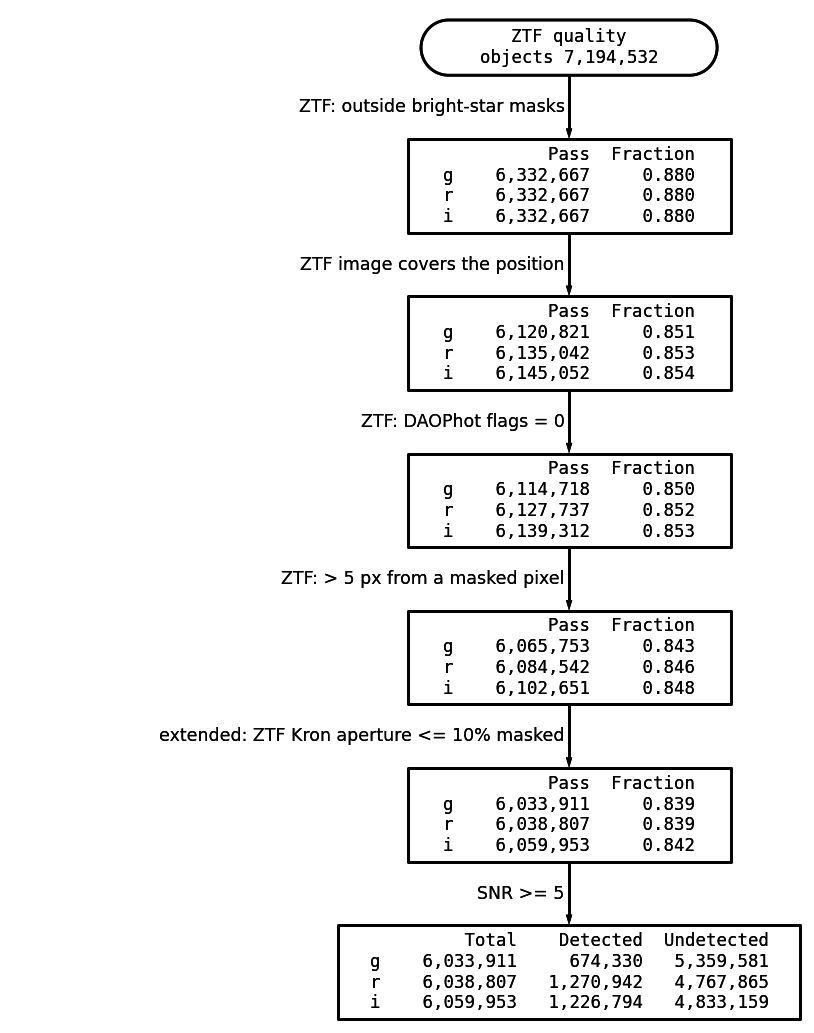

--- PS1 quality


g (start 7,194,532)                                          r (start 7,194,532)                                          i (start 7,194,532)             \
                                                  after total fail total fail %  unique unique %               after total fail total fail %  unique unique %               after total fail   
check                                                                                                                                                                                          
PS1: not in a flagged polar skycell           7,144,733     49,799         0.69  49,202     0.68           7,144,733     49,799         0.69  48,842     0.68           7,144,733     49,799   
PS1: catalog covers the position              7,144,733          0         0.00       0     0.00           7,144,733          0         0.00       0     0.00           7,144,733          0   
PS1: objects within 1' in the band            7,144,733          0         0.00       0     0.00           7,144,733          0         0.00       0     0.00           7,144,733          0   
PS1: residual sky <= 1e-07                    7,132,574     12,159         0.17  10,081     0.14           7,097,449     47,328         0.66  43,173     0.60           7,111,431     33,306   
PS1: stack nFrames >= 4                       7,051,604     82,612         1.15  32,838     0.46           7,019,767     81,367         1.13  28,748     0.40           7,061,143     51,506   
PS1: not DEFECT                               7,047,804     34,778         0.48   3,437     0.05           7,015,439     35,946         0.50   4,034     0.06           7,054,908     37,806   
PS1: not PEAK_ON_SPIKE                        7,046,902     33,170         0.46     128     0.00           7,014,410     34,672         0.48     155     0.00           7,053,949     34,017   
PS1: not ON_SPIKE                             7,046,691     33,131         0.46       0     0.00           7,014,265     34,405         0.48       0     0.00           7,053,826     33,609   
PS1: not ON_STARCORE                          7,043,859     39,013         0.54       0     0.00           7,011,510     40,674         0.57       0     0.00           7,050,318     40,657   
PS1: not ON_BURNTOOL                          7,043,095      2,899         0.04       0     0.00           7,010,840      2,784         0.04       0     0.00           7,050,207      1,066   
PS1: not SATSTAR                              7,042,590      2,595         0.04       7     0.00           7,010,236      3,193         0.04       5     0.00           7,049,382      3,449   
PS1: not SATSTAR_PROFILE                      7,042,590     31,652         0.44       0     0.00           7,010,236     32,466         0.45       0     0.00           7,049,382     32,712   
PS1: measured in the band                     7,041,258     34,882         0.48       0     0.00           7,009,238     35,169         0.49       0     0.00           7,048,823     34,771   
PS1: psfQfPerfect > 0.85                      7,038,007     59,872         0.83   3,251     0.05           7,006,914     60,080         0.84   2,324     0.03           7,046,457     56,637   

                                                                   
                                    total fail %  unique unique %  
check                                                              
PS1: not in a flagged polar skycell         0.69  49,374     0.69  
PS1: catalog covers the position            0.00       0     0.00  
PS1: objects within 1' in the band          0.00       0     0.00  
PS1: residual sky <= 1e-07                  0.46  31,547     0.44  
PS1: stack nFrames >= 4                     0.72   4,154     0.06  
PS1: not DEFECT                             0.53   5,792     0.08  
PS1: not PEAK_ON_SPIKE                      0.47      93     0.00  
PS1: not ON_SPIKE                           0.47       0     0.00  
PS1: not ON_STARCORE   

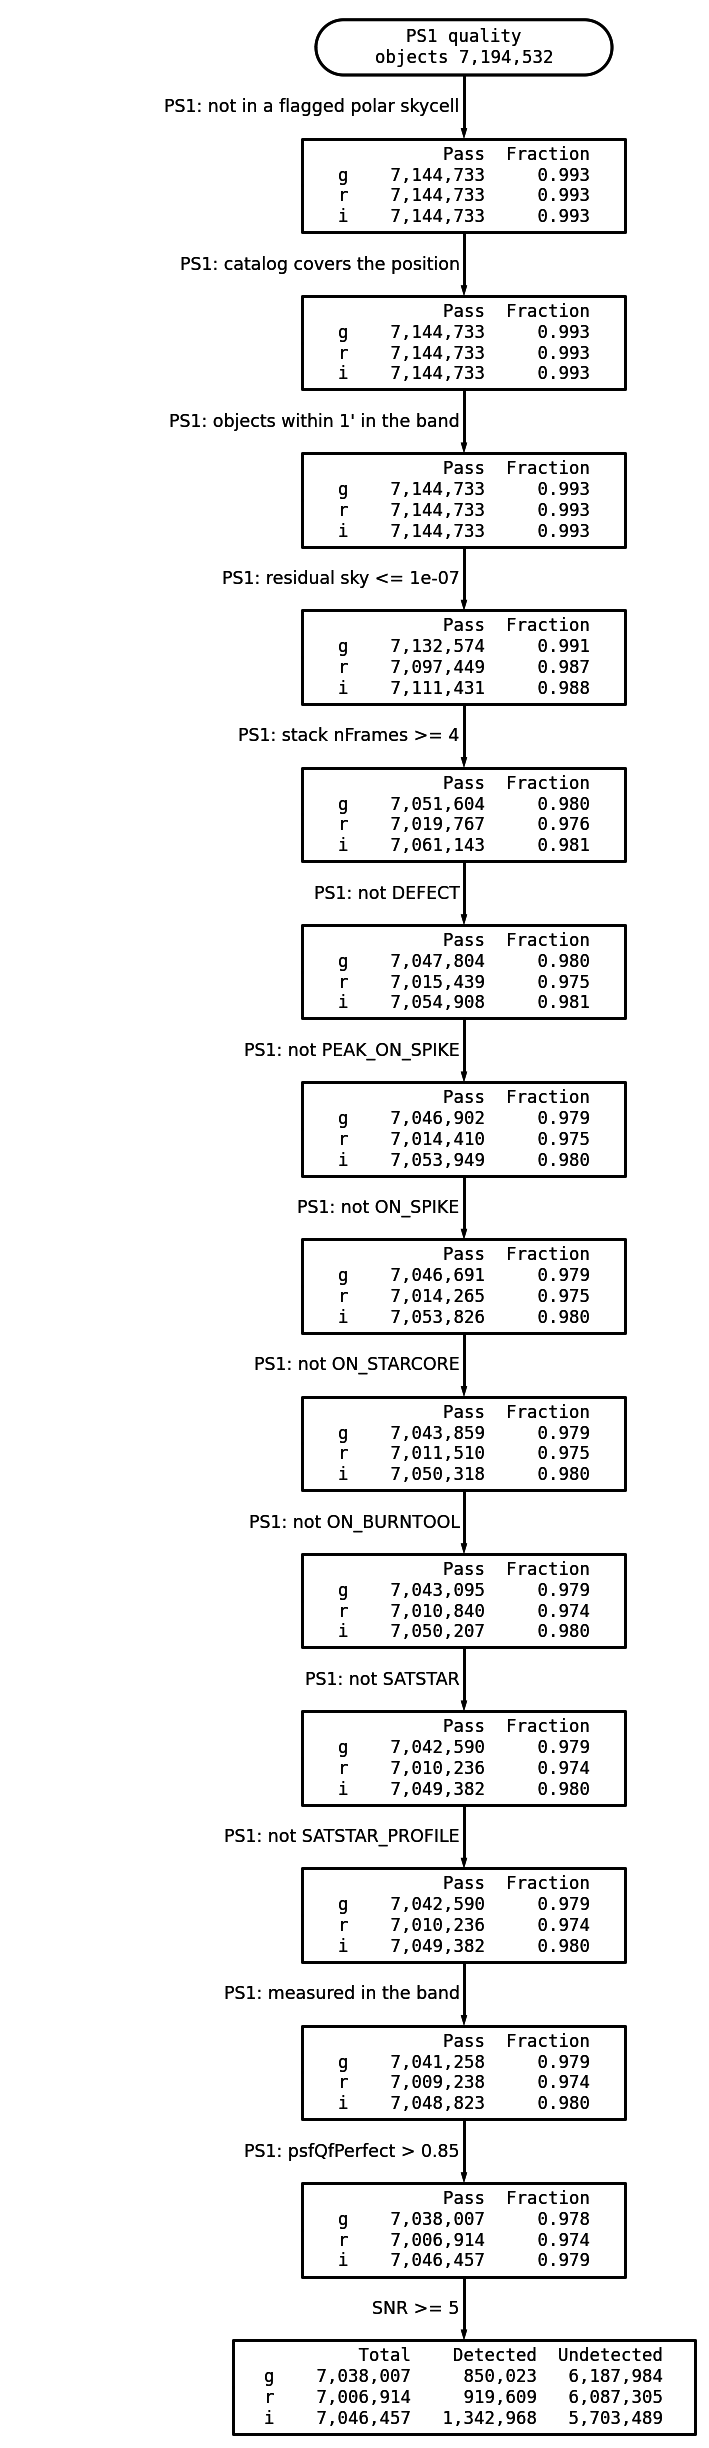

In [ ]:
for sv in ('ztf', 'ps1'):
    print(f'--- {ff.SURVEY_NAME[sv]} quality')
    display(quality_block(sv))
    display(ff.quality_flowchart(src, sv, CUTS, table=QT[sv]))

In [ ]:
for name in NAMES:                                  # objects whose S/N ≥ 5 measurements would put them in `name`
    cutouts_quality('ztf', catalog=name)
    cutouts_quality('ps1', catalog=name)

saved 5 checks → /Users/adamboesky/Research/long_transients2/Data/fields/000860/review/filter_cutouts/quality_ztf/in_both.png
saved 14 checks → /Users/adamboesky/Research/long_transients2/Data/fields/000860/review/filter_cutouts/quality_ps1/in_both.png
saved 5 checks → /Users/adamboesky/Research/long_transients2/Data/fields/000860/review/filter_cutouts/quality_ztf/in_ztf.png
saved 14 checks → /Users/adamboesky/Research/long_transients2/Data/fields/000860/review/filter_cutouts/quality_ps1/in_ztf.png
saved 5 checks → /Users/adamboesky/Research/long_transients2/Data/fields/000860/review/filter_cutouts/quality_ztf/in_pstarr.png
saved 14 checks → /Users/adamboesky/Research/long_transients2/Data/fields/000860/review/filter_cutouts/quality_ps1/in_pstarr.png


**Where PS1 says nothing.** Three PS1 checks judge the position rather than a measurement: MAST's mis-registered
polar skycells (`badcells_near_north_pole_v6.dat`; every magnitude there is −999 while fluxes remain; with or without a
PS1 object), and, without a PS1 object, DR2's missing-catalog regions and positions where PS1 measured nothing in the
band within 1′. Bad skycells are also excluded from both recovery-limit references (section 7).

no PS1 object, no PS1 object measured within 1′: {'g': 0, 'r': 0, 'i': 0}


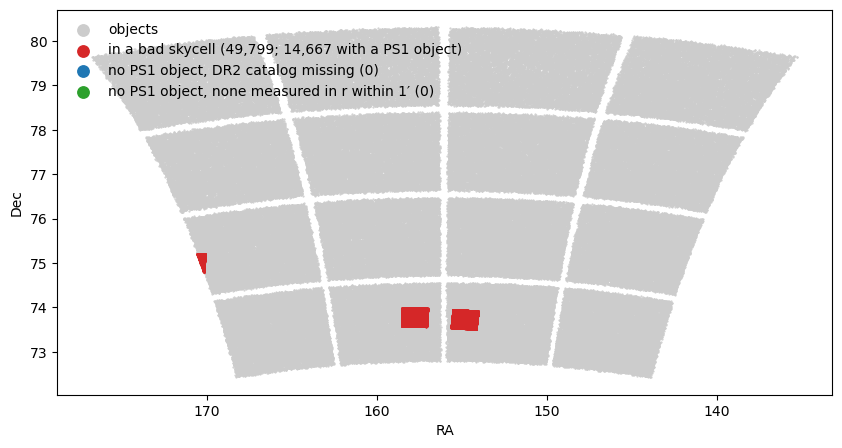

In [ ]:
has = src.ps1_idx.values >= 0
bad, missing = ff.ps1_skycell_bad(src), src.ps1_catalog_missing.values
uncovered = {b: ~has & ~src[f'{b}_ps1_covered'].values for b in 'gri'}
print('no PS1 object, no PS1 object measured within 1′:', {b: int(v.sum()) for b, v in uncovered.items()})
fig, ax = plt.subplots(figsize=(10, 5))
s = src.sample(300_000, random_state=0)
ax.scatter(s.ra, s.dec, s=0.3, color='0.8', rasterized=True, label='objects')
ax.scatter(src.ra[bad], src.dec[bad], s=0.3, color='C3', rasterized=True, label=f'in a bad skycell ({bad.sum():,}; {int((bad & has).sum()):,} with a PS1 object)')
ax.scatter(src.ra[missing], src.dec[missing], s=0.3, color='C0', rasterized=True, label=f'no PS1 object, DR2 catalog missing ({missing.sum():,})')
ax.scatter(src.ra[uncovered['r']], src.dec[uncovered['r']], s=0.3, color='C2', rasterized=True, label=f"no PS1 object, none measured in r within 1′ ({uncovered['r'].sum():,})")
ax.invert_xaxis(); ax.set_xlabel('RA'); ax.set_ylabel('Dec'); ax.legend(frameon=False, markerscale=15); plt.show()

## 3. Detection (per band, per usable side: D / L / U)

- `ff.detection_status` — what each survey has in the band, independent of quality:
  **D** measured at S/N ≥ 5 · **L** measured below 5 (a ZTF detection under 5; a PS1 measurement, forced fluxes ≤ 0
  included): used if brighter than the survey's limit, else the limit · **U** nothing measured (no ZTF detection, no PS1
  object): the survey's completeness limit stands in.
- `ff.ztf_detected` — a ZTF detection is a finite `{b}_ztf_psf`; PS1's S/N is `{b}_ps1_snr` (`ff.load_merged`).
- `ff.band_status` — the detection status on usable sides (`ff.usable_sides`), **X** on the others: `{b}_ztf_status`, `{b}_ps1_status`.

Detection drops nothing, so it is not a waterfall step. Band r, every object: detection status alone, which sides are
usable, then the combined status.

PS1 r detection,D,L,U,All
D,707972,360385,462253,1530610
L,9526,98269,1592837,1700632
U,255365,864960,2842965,3963290
All,972863,1323614,4898055,7194532


PS1 r usable,False,True,All
False,55224,1100501,1155725
True,132394,5906413,6038807
All,187618,7006914,7194532


PS1 r,D,L,U,X,All
D,612834,313288,307828,36992,1270942
L,8116,88622,1414468,13419,1524625
U,140250,642347,2378660,81983,3243240
X,158409,180125,761967,55224,1155725
All,919609,1224382,4862923,187618,7194532


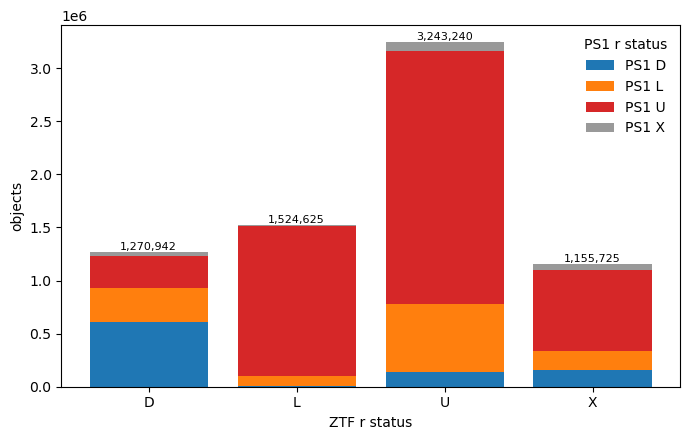

In [ ]:
z, p = ff.detection_status(src, 'r')
z_ok, p_ok = ff.usable_sides(src, 'r', src.point_source.values, CUTS)
assert (np.where(z_ok, z, 'X') == src.r_ztf_status.values).all() and (np.where(p_ok, p, 'X') == src.r_ps1_status.values).all()
with_all = lambda t: t.assign(All=t.sum(axis=1)).pipe(lambda t: pd.concat([t, t.sum().rename('All').to_frame().T]))
display(with_all(pd.crosstab(pd.Series(z, name='ZTF r detection'), pd.Series(p, name='PS1 r detection'))))
display(with_all(pd.crosstab(pd.Series(z_ok, name='ZTF r usable'), pd.Series(p_ok, name='PS1 r usable'))))
ct = pd.crosstab(src.r_ztf_status.rename('ZTF r'), src.r_ps1_status.rename('PS1 r'))
display(with_all(ct))

fig, ax2 = plt.subplots(figsize=(7, 4.5))
bottom = np.zeros(len(ct))
for col, color in zip(ct.columns, ('C0', 'C1', 'C3', '0.6')):
    ax2.bar(ct.index, ct[col], bottom=bottom, label=f'PS1 {col}', color=color); bottom += ct[col].values
for i, tot in enumerate(ct.sum(axis=1)):
    ax2.text(i, tot, f'{tot:,}', ha='center', va='bottom', fontsize=8)
ax2.set_xlabel('ZTF r status'); ax2.set_ylabel('objects'); ax2.legend(frameon=False, title='PS1 r status')
plt.tight_layout(); plt.show()

## 4. Comparison and sorting

- `ff.COMPARISON` / `ff.comparison` — the (ZTF, PS1) status pair → what the band compares, `{b}_cat` (table below).
- `ff.object_catalog` — the object's `catalog` from the kinds its bands carry, or −1 with `catalog_reason`.
- `ff.point_source` / `ff.extendedness` — one morphology per object: extended if (PSF − Kron − 0.05)/σ > 3 in ≥ 2 measured bands.
- `ff.assign_catalogs` — runs `ff.completeness_limits` (section 7: the model limits), the statuses, `{b}_cat`, `catalog`, `point_source`,
  `{b}_ztf_use_meas` / `{b}_ps1_use_forced`; the photometry every later step reads is the morphology's (`ff.band_photometry`: PSF for a point source, Kron for an extended object).
- `ff.compared_magnitudes` — (ZTF, error, PS1, error) the band compares: PSF or Kron, measurement or limit.
- `ff.sort_table` — objects by the bands with a comparison of any kind (before an `in_both` object drops its one-sided
  bands) against the catalog they are sorted into. The first place band combinations appear.

Per band (`{b}_cat`: 0 two-sided, 1 ZTF vs PS1 limit, 2 PS1 vs ZTF limit, −1 nothing):

| ZTF ╲ PS1 | **D** | **L** | **U** | **X** |
|---|---|---|---|---|
| **D** | ZTF vs PS1 (two-sided) | ZTF vs PS1 limit* | ZTF vs PS1 limit | nothing |
| **L** | PS1 vs ZTF limit* | nothing | nothing | nothing |
| **U** | PS1 vs ZTF limit | nothing | nothing | nothing |
| **X** | nothing | nothing | nothing | nothing |

\* The S/N < 5 measurement (PS1's forced flux, ZTF's catalog value) is compared instead of the limit if it is brighter
than the limit or at S/N ≥ 3 (`ff.FORCED_SNR_MIN`); otherwise the limit.

Per object (`ff.object_catalog`): ≥ 2 two-sided bands → `in_both` (its one-sided bands are dropped), or one two-sided band plus
≥ 1 D/L band (the other survey measured the position; D/U bands are dropped) → `in_both` · else ≥ 2 bands
all "ZTF vs PS1 limit" → `in_ztf` · all "PS1 vs ZTF limit" → `in_pstarr` · anything else → **not comparable**, with
`catalog_reason` (fewer than two measured bands, no comparable band, one comparable band, one two-sided band, mixed
one-sided kinds).

Worked cases, one row per object (cells are ZTF/PS1 status per band):

| # | g | r | i | catalog | outcome |
|:-:|:-:|:-:|:-:|---|---|
| 1 | D/D | D/D | D/D | in_both | g, r, i two-sided |
| 2 | D/D | D/L | D/L | in_both | g two-sided · r, i: ZTF vs PS1 forced flux or limit* |
| 2′ | D/D | D/U | D/U | not comparable | one two-sided band (PS1 has no object in r, i: the absence may be a catalog miss) |
| 3 | D/D | D/X | D/X | not comparable | one two-sided band |
| 4 | D/L | D/L | D/L | in_ztf | g, r, i: ZTF vs PS1 limit* |
| 4′ | L/D | L/D | L/D | in_pstarr | g, r, i: PS1 vs ZTF limit* |
| 5 | L/D | D/D | D/D | in_both | g dropped · r, i two-sided |
| 6 | U/D | D/D | D/D | in_both | g dropped · r, i two-sided |
| 7 | X/D | D/D | D/D | in_both | g dropped · r, i two-sided |
| 8 | D/D | D/D | D/X | in_both | g, r two-sided · i dropped |
| 9 | L/L | L/L | D/D | not comparable | one two-sided band |
| 10 | D/U | D/U | D/U | in_ztf | g, r, i: ZTF vs PS1 limit |
| 11 | D/U | D/U | U/U | in_ztf | g, r: ZTF vs PS1 limit |
| 12 | D/U | L/U | U/U | not comparable | one comparable band |
| 13 | U/D | U/D | U/D | in_pstarr | g, r, i: PS1 vs ZTF limit |
| 14 | U/D | U/D | U/L | in_pstarr | g, r: PS1 vs ZTF limit |
| 15 | U/D | U/X | U/X | not comparable | one comparable band |
| 16 | U/D | U/D | U/X | in_pstarr | g, r: PS1 vs ZTF limit · i dropped |
| 17 | X/D | X/D | X/D | not comparable | ZTF side unusable (e.g. not covered): no comparable band |
| 18 | L/L | L/L | L/L | not comparable | no comparable band |
| 19 | D/X | D/X | D/X | not comparable | PS1 side X in every band (e.g. a bad polar skycell): no comparable band |
| 20 | D/L | D/L | X/D | in_ztf | g, r: ZTF vs PS1 limit (PS1's i detection has no usable ZTF side) |
| 21 | D/L | U/D | U/D | not comparable | mixed one-sided kinds |

Quality acts before sorting, so a ZTF object whose PS1 match is X in every band is not comparable rather than `in_ztf`.
PS1's BAD_STACK / SUSPECT_STACK are not quality checks: such an object sorts by its statuses and meets the flags in
section 5.

In the table below, *alone* / *unique* of the comparable step count a band as comparable when either side has S/N ≥ 5,
independent of quality (the chain's own step reads the statuses, which already carry the X's).

In [ ]:
display(ff.sort_table(src))

catalog,in_both,in_ztf,in_pstarr,not comparable,total
gri,459570,14929,2235,65299,542033
gr,13984,16640,5195,11421,47240
gi,12753,6025,4464,13462,36704
ri,114090,73511,5988,220960,414549
g,0,0,0,320332,320332
r,0,0,0,378494,378494
i,0,0,0,444865,444865
none,0,0,0,5010315,5010315
total,600397,111105,17882,6465148,7194532


### Sorting into catalogs

At the end of the shared stage each object either has ≥ 2 comparable bands of one kind — its catalog — or is not
comparable, with a reason. Objects with a measurement in one band only never enter the shared-stage table.

,"not comparable, by reason"
catalog_reason,
fewer than two measured bands,4517106
no comparable band,867467
one comparable band,650783
one two-sided band,368891
mixed one-sided kinds,60901


,objects,of which ≥ 2 measured bands
catalog,,
not comparable,6465148,1948042
in_both,600397,600397
in_ztf,111105,111105
in_pstarr,17882,17882


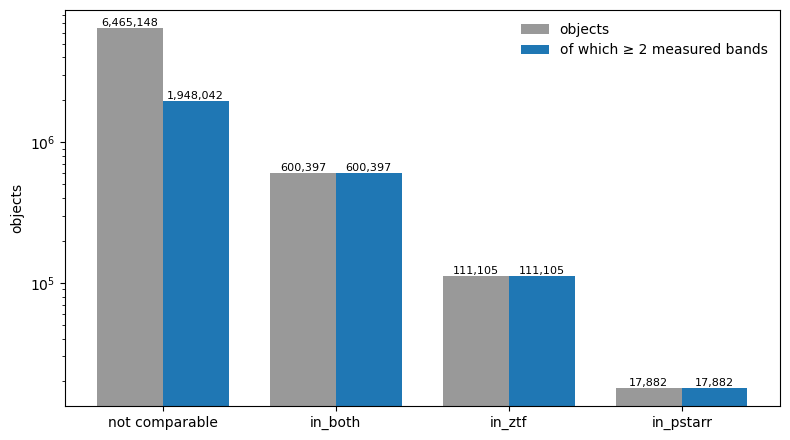

In [ ]:
start = {name: int(wfs[name].stats.objects.iloc[0]) for name in NAMES}
counts = pd.DataFrame({'objects': src.catalog.map({**ff.CATALOG, -1: 'not comparable'}).value_counts()})
counts['of which ≥ 2 measured bands'] = [int(((src.catalog.map({**ff.CATALOG, -1: 'not comparable'}) == k) & (sum(ff.ztf_detected(src, b) | src[f'{b}_ps1_meas'] for b in 'gri') >= 2)).sum()) for k in counts.index]
display(src.catalog_reason[src.catalog < 0].value_counts().rename('not comparable, by reason').to_frame())
display(counts)

fig, ax1 = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(counts)); w = 0.38
ax1.bar(x - w / 2, counts.objects, w, label='objects', color='0.6')
ax1.bar(x + w / 2, counts['of which ≥ 2 measured bands'], w, label='of which ≥ 2 measured bands', color='C0')
for i, (a_, b_) in enumerate(zip(counts.objects, counts['of which ≥ 2 measured bands'])):
    ax1.text(i - w / 2, a_, f'{a_:,}', ha='center', va='bottom', fontsize=8)
    if b_: ax1.text(i + w / 2, b_, f'{b_:,}', ha='center', va='bottom', fontsize=8)
ax1.set_xticks(x); ax1.set_xticklabels(counts.index); ax1.set_yscale('log'); ax1.set_ylabel('objects'); ax1.legend(frameon=False)
plt.tight_layout(); plt.show()

In [ ]:
# the (ZTF/PS1 per band) status patterns actually seen, per catalog, and what the pipeline does with them (one groupby, not a scan per pattern)
KIND = {0: 'two-sided', 1: 'ZTF vs PS1 limit', 2: 'PS1 vs ZTF limit'}
pat = pd.Series('', index=src.index)
for b in 'gri':
    pat = pat + src[f'{b}_ztf_status'].astype(str) + '/' + src[f'{b}_ps1_status'].astype(str) + ('  ' if b != 'i' else '')
df = pd.DataFrame({'catalog': src.catalog.map({**ff.CATALOG, -1: 'not comparable'}).values, 'pattern': pat.values, 'reason': src.catalog_reason.values,
                   **{f'{b}_cat': src[f'{b}_cat'].values for b in 'gri'}})
g = df.groupby(['catalog', 'pattern'], sort=False)
summary = g.size().rename('objects').to_frame().join(g[['reason', 'g_cat', 'r_cat', 'i_cat']].first())
def outcome(r):
    if r.reason:
        return f'not comparable: {r.reason}'
    used = [(b, KIND[int(r[f'{b}_cat'])]) for b in 'gri' if r[f'{b}_cat'] >= 0]
    return 'kept: ' + ', '.join(b for b, _ in used) + ' ' + ' / '.join(sorted({k for _, k in used}))
summary['outcome'] = summary.apply(outcome, axis=1)
for name in [*NAMES, 'not comparable']:
    t = summary.loc[name].sort_values('objects', ascending=False)
    t['%'] = (100 * t.objects / t.objects.sum()).round(1)
    print(f'--- {name} ({t.objects.sum():,} objects, {len(t)} patterns)')
    display(t[['objects', '%', 'outcome']].rename_axis('pattern (g r i)'))

--- in_both (600,397 objects, 34 patterns)


,objects,%,outcome
pattern (g r i),,,
D/D D/D D/D,352337,58.7,"kept: g, r, i two-sided"
D/L D/D D/D,63503,10.6,"kept: r, i two-sided"
U/L D/D D/D,58092,9.7,"kept: r, i two-sided"
L/L D/D D/D,36063,6.0,"kept: r, i two-sided"
U/D D/D D/D,14501,2.4,"kept: r, i two-sided"
D/D D/L D/D,12671,2.1,"kept: g, i two-sided"
L/D D/D D/D,11134,1.9,"kept: r, i two-sided"
D/D D/D X/D,10311,1.7,"kept: g, r two-sided"
D/X D/D D/D,8562,1.4,"kept: r, i two-sided"


--- in_ztf (111,105 objects, 35 patterns)


,objects,%,outcome
pattern (g r i),,,
U/U D/U D/U,41055,37.0,"kept: r, i ZTF vs PS1 limit"
L/U D/U D/U,14230,12.8,"kept: r, i ZTF vs PS1 limit"
U/L D/L D/L,12812,11.5,"kept: r, i ZTF vs PS1 limit"
D/U D/U D/U,12215,11.0,"kept: g, r, i ZTF vs PS1 limit"
D/U D/U U/U,10235,9.2,"kept: g, r ZTF vs PS1 limit"
L/L D/L D/L,4314,3.9,"kept: r, i ZTF vs PS1 limit"
D/U D/U L/U,4068,3.7,"kept: g, r ZTF vs PS1 limit"
D/U U/U D/U,4009,3.6,"kept: g, i ZTF vs PS1 limit"
D/L D/L D/L,2714,2.4,"kept: g, r, i ZTF vs PS1 limit"


--- in_pstarr (17,882 objects, 87 patterns)


,objects,%,outcome
pattern (g r i),,,
U/D U/D U/L,3962,22.2,"kept: g, r PS1 vs ZTF limit"
U/L U/D U/D,3444,19.3,"kept: r, i PS1 vs ZTF limit"
U/D U/L U/D,2368,13.2,"kept: g, i PS1 vs ZTF limit"
U/D U/D U/D,2039,11.4,"kept: g, r, i PS1 vs ZTF limit"
U/D U/X U/D,734,4.1,"kept: g, i PS1 vs ZTF limit"
...,...,...,...
L/D L/X U/D,1,0.0,"kept: g, i PS1 vs ZTF limit"
D/X U/D L/D,1,0.0,"kept: r, i PS1 vs ZTF limit"
L/D U/D X/X,1,0.0,"kept: g, r PS1 vs ZTF limit"


--- not comparable (6,465,148 objects, 1315 patterns)


,objects,%,outcome
pattern (g r i),,,
U/U L/U U/U,1234398,19.1,not comparable: fewer than two measured bands
L/U U/U U/U,1073391,16.6,not comparable: fewer than two measured bands
U/U U/U L/U,1029198,15.9,not comparable: fewer than two measured bands
X/U X/U X/U,688131,10.6,not comparable: fewer than two measured bands
U/L U/L U/L,208585,3.2,not comparable: no comparable band
...,...,...,...
L/X U/L X/L,1,0.0,not comparable: no comparable band
D/L L/L L/X,1,0.0,not comparable: one comparable band
X/X D/D U/D,1,0.0,not comparable: one two-sided band


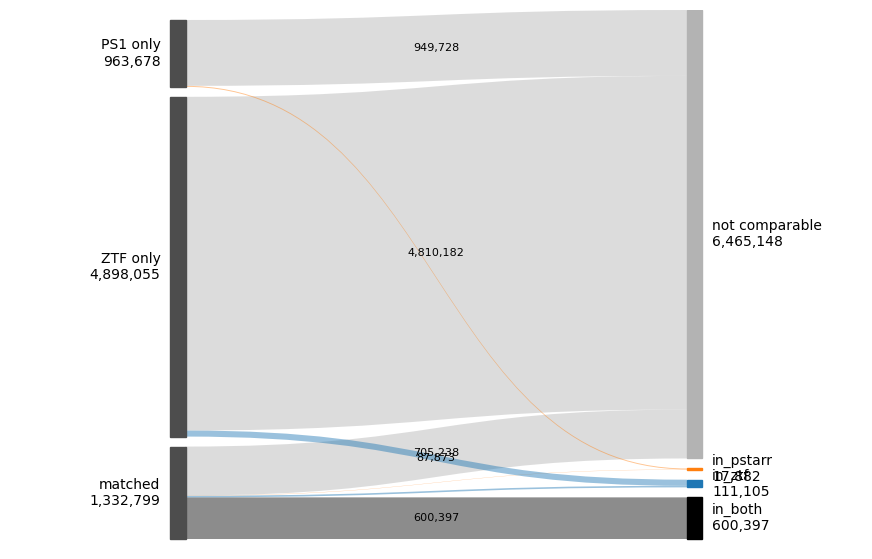

col_0,in_both,in_ztf,in_pstarr,not comparable
row_0,,,,
matched,600397,23232,3932,705238
ZTF only,0,87873,0,4810182
PS1 only,0,0,13950,949728


In [ ]:
# how the match outcome maps onto the catalogs: ribbon width = objects. Only comparable objects get a catalog; a matched
# object is one-sided when the other side never reaches D (sub-5σ forced photometry) and not comparable when it is X everywhere
from matplotlib.path import Path
from matplotlib.patches import PathPatch
left_of = np.where((src.ztf_idx >= 0) & (src.ps1_idx >= 0), 'matched', np.where(src.ztf_idx >= 0, 'ZTF only', 'PS1 only'))
right_of = src.catalog.map({**ff.CATALOG, -1: 'not comparable'}).values
L_ORDER, R_ORDER = ['matched', 'ZTF only', 'PS1 only'], ['in_both', 'in_ztf', 'in_pstarr', 'not comparable']
flow = pd.crosstab(pd.Categorical(left_of, L_ORDER), pd.Categorical(right_of, R_ORDER))
COL = {'in_both': 'k', 'in_ztf': 'tab:blue', 'in_pstarr': 'tab:orange', 'not comparable': '0.7'}
GAP, total = 0.02, flow.values.sum()
def spans(sizes):
    out, y = {}, 0.0
    for k, s in sizes.items():
        out[k] = (y, y + s / total); y += s / total + GAP
    return out
ls, rs = spans(flow.sum(axis=1)), spans(flow.sum(axis=0))
fig, ax = plt.subplots(figsize=(11, 7))
lpos = {k: v[0] for k, v in ls.items()}; rpos = {k: v[0] for k, v in rs.items()}
for l in L_ORDER:
    for r in R_ORDER:
        n = flow.loc[l, r]
        if n == 0: continue
        h = n / total; y0, y1 = lpos[l], rpos[r]
        verts = [(0, y0), (0.5, y0), (0.5, y1), (1, y1), (1, y1 + h), (0.5, y1 + h), (0.5, y0 + h), (0, y0 + h), (0, y0)]
        codes = [Path.MOVETO, Path.CURVE4, Path.CURVE4, Path.CURVE4, Path.LINETO, Path.CURVE4, Path.CURVE4, Path.CURVE4, Path.CLOSEPOLY]
        ax.add_patch(PathPatch(Path(verts, codes), facecolor=COL[r], alpha=0.45, lw=0))
        if h > 0.012: ax.text(0.5, y0 + h / 2 + (y1 - y0) / 2, f'{n:,}', ha='center', va='center', fontsize=8)
        lpos[l] += h; rpos[r] += h
for k, (a, b) in ls.items(): ax.add_patch(plt.Rectangle((-0.03, a), 0.03, b - a, color='0.3')); ax.text(-0.05, (a + b) / 2, f'{k}\n{int(flow.loc[k].sum()):,}', ha='right', va='center', fontsize=10)
for k, (a, b) in rs.items(): ax.add_patch(plt.Rectangle((1, a), 0.03, b - a, color=COL[k])); ax.text(1.05, (a + b) / 2, f'{k}\n{int(flow[k].sum()):,}', ha='left', va='center', fontsize=10)
ax.set_xlim(-0.35, 1.35); ax.set_ylim(-0.02, 1 + GAP * 3); ax.axis('off')
plt.show()
display(flow)

## 5. Confident (object-wide, per catalog)

Is it one real object? `ff.real_checks` gives each catalog's checks; `ff.cut_bands` runs them on the catalog's comparable objects, in order:
- `no other object within 3"` — `in_ztf`, `in_pstarr`: `nearest_other_arcsec` (either survey, matched or not; `ff.annotate_neighbours`, `Cuts.isolation_arcsec`).
- `ZTF: S/N²-weighted |sharp| <= 0.5 (point sources)` — all catalogs: `ff.ztf_sharpness`, `ff.sharpness_fails` (`Cuts.sharp_max`, `Cuts.sharp_point_only`).
- `PS1: nStackDetections >= 2` — `in_pstarr` only: PS1's own detection pass found the object in at least two stacks; nothing else vouches
  for an in_pstarr object, while an `in_both` object has a ZTF detection (on 860 the check removed only real faint objects from in_both).
- `PS1: not BAD_STACK`, `PS1: not SUSPECT_STACK` — `in_both`, `in_pstarr` (PS1's side is a measurement): PS1's verdict on its stack.
  `in_ztf` gets neither: there PS1's side is a limit.
- `ZTF: light not diffuse ((PSF - Kron - 0.5)/σ <= 3)` / `PS1: light not diffuse (...)` — `in_ztf` on ZTF's side, `in_pstarr` on PS1's
  (`ff.diffuse_light`, `Cuts.diffuse_excess`, `Cuts.diffuse_nsigma`): the morphology statistic with a 0.5 mag offset. A one-sided object
  whose only light is a sheet 0.5 mag beyond the PSF in two bands is scattered light in the image (on this field: stack sheets with no
  single-epoch detections, model half-light radii of 30–50″), not a source that appeared or vanished. `in_both`'s extended objects,
  seen by both surveys, are galaxies and are left alone.

The bright-star mask is a ZTF quality check (section 2); the Kron-containment check (`Cuts.neighbour_kron`) is off.

In [ ]:
display(catalog_block('confident'))

in_both (start 600,397)                                         in_ztf (start 111,105)                                          \
                                                                    after total fail total fail % unique unique %                  after total fail total fail % unique unique %   
check                                                                                                                                                                              
no other object within 3"                                               –          –            –      –        –                 75,184     35,921        32.33    152     0.14   
outside every brighter object's Kron aperture                           –          –            –      –        –                 67,361     22,683        20.42    273     0.25   
ZTF: S/N²-weighted |sharp| <= 0.5 (point sources)                 600,208        189         0.03     27     0.00                 67,303      3,559         3.20     41     0.04   
PS1: nStackDetections >= 2                                        596,748      3,538         0.59     29     0.00                      –          –            –      –        –   
PS1: not BAD_STACK                                                593,561      3,187         0.53      3     0.00                      –          –            –      –        –   
PS1: not SUSPECT_STACK                                            593,545         16         0.00      0     0.00                      –          –            –      –        –   

                                                  in_pstarr (start 17,882)                                          
                                                                     after total fail total fail % unique unique %  
check                                                                                                               
no other object within 3"                                            6,086     11,796        65.97    119     0.67  
outside every brighter object's Kron aperture                        5,253      8,857        49.53     48     0.27  
ZTF: S/N²-weighted |sharp| <= 0.5 (point sources)                    5,197        130         0.73      0     0.00  
PS1: nStackDetections >= 2                                           3,474      6,127        34.26     89     0.50  
PS1: not BAD_STACK                                                   3,136      1,116         6.24     12     0.07  
PS1: not SUSPECT_STACK                                               3,134          6         0.03      0     0.00

In [ ]:
for name in NAMES:
    cutouts_catalog('confident', name)

saved 4 checks → /Users/adamboesky/Research/long_transients2/Data/fields/000860/review/filter_cutouts/confident/in_both.png
saved 3 checks → /Users/adamboesky/Research/long_transients2/Data/fields/000860/review/filter_cutouts/confident/in_ztf.png
saved 6 checks → /Users/adamboesky/Research/long_transients2/Data/fields/000860/review/filter_cutouts/confident/in_pstarr.png


## 6. Population

- `ff.gaia_pm_significance` — total proper motion over its error, the pmra / pmdec errors propagated in quadrature.
- `ff.gaia_population_ok` — (no proper motion at 5σ, no parallax at 5σ; `ff.GAIA_NSIGMA`), True without a Gaia match.
- Steps `Gaia: no proper motion at 5σ`, `Gaia: no parallax at 5σ` (`ff.population_checks`, run by `ff.cut_bands`).

In [ ]:
display(catalog_block('population'))
for name in NAMES:
    cutouts_catalog('population', name)
GAIA = 'Gaia: no parallax at 5σ'
reach = {name: wfs[name].mask(wfs[name].steps.index(GAIA)) for name in NAMES}

in_both (start 600,397)                                         in_ztf (start 111,105)                                         in_pstarr (start 17,882)             \
                                               after total fail total fail % unique unique %                  after total fail total fail % unique unique %                    after total fail   
check                                                                                                                                                                                             
Gaia: no proper motion at 5σ                 454,916    139,356        23.21     22     0.00                 66,695      1,589         1.43      1     0.00                    3,118        868   
Gaia: no parallax at 5σ                      454,604     65,192        10.86      0     0.00                 66,694        624         0.56      0     0.00                    3,118        464   

                                                           
                             total fail % unique unique %  
check                                                      
Gaia: no proper motion at 5σ         4.85      1     0.01  
Gaia: no parallax at 5σ              2.59      0     0.00

saved 2 checks → /Users/adamboesky/Research/long_transients2/Data/fields/000860/review/filter_cutouts/population/in_both.png
saved 2 checks → /Users/adamboesky/Research/long_transients2/Data/fields/000860/review/filter_cutouts/population/in_ztf.png
saved 2 checks → /Users/adamboesky/Research/long_transients2/Data/fields/000860/review/filter_cutouts/population/in_pstarr.png


## 7. Calibrate (on what is left)

Each survey's detection limit per band is a model of the image, not a recovery measured on this field:
- `ff.ztf_recovery_mag` — `{b}_ztf_rec90_limit`: the magnitude at which the reference image detects 90 % of point sources at S/N ≥ 5,
  from the catalog's 5σ depth `{b}_ztf_mag_5sigma` and η = `{b}_ztf_gpctsig` / `{b}_ztf_medpunc`, the image's real pixel scatter over the
  pipeline's modelled one (coadding correlates the noise the model leaves independent). Derived in `Notebooks/recovery_completeness.ipynb`.
- `ps1_stack.stack_recovery_mag` / `ff.ps1_limit` — `{b}_ps1_rec90_limit`: PS1's own injection-recovery test of the deep stack the band
  is judged in (`StackDetEffMeta`, `Data/ps1/stack_deteff_gri.parquet`), the magnitude where the recovered fraction falls to 90 %; NaN
  where there is no stack or it never gets there, which the quality check `PS1: stack reaches 90% at the position` turns into an X.
- `ff.clip_envelope_sample` — the two-sided bands that reach the |σ| step, clipped at 5 MAD-σ of the rolling median of Δmag, measured on
  the envelope's own rows and windows (`ff.rolling_median_mad`, `Cuts.envelope_clip_mad`).
- `ff.envelope_tables`, `ff.kde_envelopes` — one rolling KDE envelope per band **and per morphology** (`ff.MORPHOLOGIES`: point sources
  from their PSF Δmag, extended objects from their Kron Δmag), from 16 mag in ±0.5 mag windows; a row with fewer than 50 objects takes
  the nearest measured row (`ff.ENVELOPE_MIN_PER_ROW`); `ff.widen_faint_rows` beyond 20 mag.

### Cross-check: measured recovery against the model limits

Each survey's detections at S/N ≥ 5 (passing that survey's quality checks), binned by their PSF magnitude, and the fraction the other
survey measured at the 1″ match. Dashed: the median of the other survey's model limit. The curve should cross 90 % near the line.

In [ ]:
edges = np.arange(17, 24.01, 0.25); mid = edges[:-1] + 0.125
def curve(mag, ref, rec):
    n = np.histogram(mag[ref], edges)[0]; d = np.histogram(mag[ref & rec], edges)[0]
    return np.where(n >= 20, d / np.maximum(n, 1), np.nan)
def vline(ax, x, color, y, ls='--'):
    if np.isfinite(x):
        ax.axvline(x, color=color, ls=ls, lw=1.2); ax.text(x, y, f'{x:.2f}', color=color, fontsize=9, rotation=90, ha='right', va='top')
point = src.point_source.values
fig, axes = plt.subplots(2, 3, figsize=(16, 7.5), sharex=True, sharey=True)
for ax, b in zip(axes[0], 'gri'):                                     # ZTF recovers PS1's detections -> ZTF's limit
    ref = src[f'{b}_ps1_detected'].values & (ff.band_photometry(src, b, 'ps1')[2] >= ff.SNR_MIN) & ff._passes(ff.ps1_checks(src, b, src.point_source.values, CUTS)) & src[f'{b}_ztf_covered'].values
    ax.plot(mid, curve(src[f'{b}_ps1_psf'].values, ref, ff.ztf_detected(src, b)), color='C0', lw=2, label=f'ZTF recovers PS1 {b} ({ref.sum():,})')
    vline(ax, np.nanmedian(src[f'{b}_ztf_maglim_header']), 'k', 0.55, ls='-'); vline(ax, np.nanmedian(src[ff.limit_col('ztf', b)]), 'C0', 0.35)
    ax.legend(frameon=False, fontsize=8, loc='lower left')
for ax, b in zip(axes[1], 'gri'):                                     # PS1 recovers ZTF's detections -> PS1's limit
    ref = ff.ztf_detected(src, b) & (src[f'{b}_ztf_snr'].values >= ff.SNR_MIN) & ff._passes(ff.ztf_checks(src, b, point, CUTS)) & np.isfinite(src[ff.limit_col('ps1', b)].values)
    ax.plot(mid, curve(src[f'{b}_ztf_psf'].values, ref, src[f'{b}_ps1_meas'].values), color='C1', lw=2, label=f'PS1 recovers ZTF {b} ({ref.sum():,})')
    vline(ax, ps1_stack.STACK_5SIG[b], 'k', 0.55, ls='-'); vline(ax, np.nanmedian(src[ff.limit_col('ps1', b)]), 'C1', 0.35)
    ax.set_xlabel(f'{b} mag'); ax.legend(frameon=False, fontsize=8, loc='lower left')
for ax in axes.ravel(): ax.axhline(0.9, color='k', lw=0.6, ls=':'); ax.set_ylim(0, 1.02); ax.set_xlim(17, 24)
axes[0, 0].set_ylabel('ZTF recovered fraction'); axes[1, 0].set_ylabel('PS1 recovered fraction')
plt.tight_layout(); plt.show()

### The model limits

Per object: ZTF's limit against the image's header MAGLIM, and PS1's against the stack's input frames. A NaN PS1 limit is an X on that
side unless PS1 detected the object (section 2).

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, b in zip(axes[0], 'gri'):
    zl, hm = src[ff.limit_col('ztf', b)].values, src[f'{b}_ztf_maglim_header'].values; ok = np.isfinite(zl) & np.isfinite(hm)
    ax.hexbin(hm[ok], zl[ok], gridsize=60, bins='log', cmap='Greys', mincnt=1)
    lim = (19.5, 23.5); ax.plot(lim, lim, color='C3', lw=0.8); ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel(f'{b}: header MAGLIM of the image'); ax.set_ylabel(f'{b}: ZTF 90 % limit (model)')
    ax.text(0.03, 0.97, f'NaN: {np.isnan(zl).mean():.1%} of objects', transform=ax.transAxes, va='top', fontsize=9)
for ax, b in zip(axes[1], 'gri'):
    n, pl = src[f'{b}_ps1_nFrames'].values, src[ff.limit_col('ps1', b)].values; ok = np.isfinite(pl) & (n > 0)
    ax.hexbin(n[ok], pl[ok], gridsize=(40, 60), bins='log', cmap='Greys', mincnt=1)
    ax.axhline(ps1_stack.STACK_5SIG[b], color='C3', lw=0.8, label='published 5σ stack depth')
    ax.set_xlabel(f'{b}: PS1 stack nFrames at the object'); ax.set_ylabel(f'{b}: PS1 90 % limit (injection)'); ax.legend(frameon=False, fontsize=8)
    ax.text(0.03, 0.97, f'NaN: {np.isnan(pl).mean():.1%} of objects', transform=ax.transAxes, va='top', fontsize=9)
plt.tight_layout(); plt.show()

### Envelopes, one per morphology

Each is built from the two-sided bands that reach the |σ| step (S/N ≥ 5 both sides) of one morphology, in that morphology's compared
magnitudes: point sources' PSF Δmag, extended objects' Kron Δmag, each sample clipped on its own. One envelope for both would be as
narrow as the point sources that dominate it, while a Kron Δmag scatters several times more at the faint end: ordinary faint galaxies
would reach 3σ, and the clipping would throw their own tail out of the sample (`Notebooks/envelope_by_morphology_860.ipynb`).
Rows: point, extended. Lines: ±1, 2σ dashed; ±3σ (the threshold) and ±4σ solid.

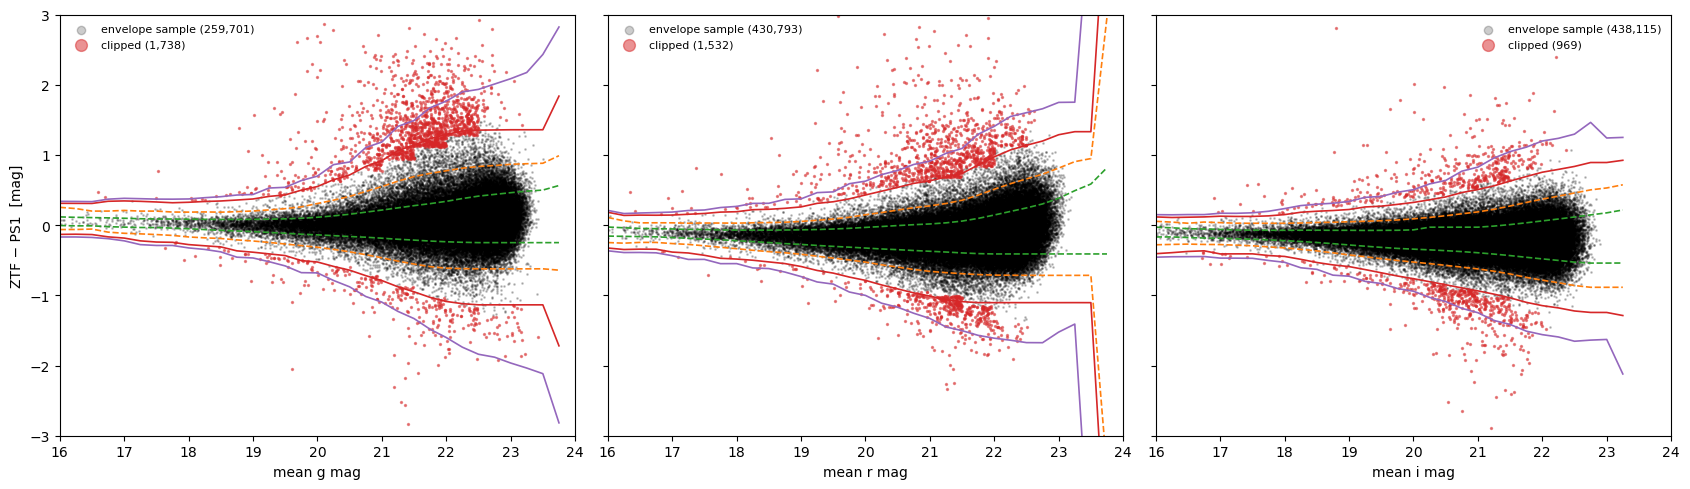

In [ ]:
reach_any = {b: np.logical_or.reduce([reach[name][b] for name in NAMES]) for b in 'gri'}
morph = ff.morphology(src)
LEVELS = [(-4, 'C4'), (-3, 'C3'), (-2, 'C1'), (-1, 'C2'), (1, 'C2'), (2, 'C1'), (3, 'C3'), (4, 'C4')]
fig, axes = plt.subplots(2, 3, figsize=(17, 9.5), sharey=True, sharex=True)
rng = np.random.default_rng(0)
for row, m in enumerate(ff.MORPHOLOGIES):
    use = {b: reach_any[b] & (morph == m) for b in 'gri'}
    sample = ff.clip_envelope_sample(src, use, CUTS.envelope_clip_mad)
    for ax, b in zip(axes[row], 'gri'):
        two_sided = (src[f'{b}_cat'].values == 0) & use[b]
        zu, _, pu, _ = ff.compared_magnitudes(src, b); mag = (zu + pu) / 2; d = src[f'{b}_dmag'].values
        show = rng.random(len(src)) < 0.3
        kept, clipped = two_sided & sample[b], two_sided & ~sample[b]
        ax.scatter(mag[kept & show], d[kept & show], s=1, alpha=0.2, color='k', rasterized=True, label=f'{m} envelope sample ({kept.sum():,})')
        ax.scatter(mag[clipped], d[clipped], s=2, alpha=0.5, color='C3', rasterized=True, label=f'clipped ({clipped.sum():,})')
        for n_, c in LEVELS:
            ax.plot(env[m][b].mag_grid, env[m][b].get_percentile(env[m][b].mag_grid, norm.cdf(n_)), color=c, lw=1.2, ls='-' if abs(n_) >= 3 else '--')
        ax.set_xlim(16, 24); ax.set_ylim(-3, 3); ax.legend(frameon=False, fontsize=8, markerscale=6)
        if row == 1: ax.set_xlabel(f'mean {b} mag')
    axes[row, 0].set_ylabel(f'{m}: ZTF − PS1  [mag]')
plt.tight_layout(); plt.show()

# the two envelopes side by side: full width between the ±3σ edges per magnitude row
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for ax, b in zip(axes, 'gri'):
    for m, c in zip(ff.MORPHOLOGIES, ('C0', 'C2')):
        lo, hi = env[m][b].get_percentile(env[m][b].mag_grid, [norm.cdf(-3), norm.cdf(3)]); ax.plot(env[m][b].mag_grid, hi - lo, color=c, label=m)
    ax.set_xlabel(f'{b}: mean magnitude'); ax.set_ylabel('width of the ±3σ envelope [mag]'); ax.set_yscale('log'); ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

## 8. Interesting

- `ff.annotate_sigma` — `{b}_dmag` (ZTF − PS1 of the compared magnitudes) and `{b}_sigma` against the band's envelope of the
  object's morphology (`ff.Envelope_KDE.sigma`; ZTF brighter = negative). Against the PS1 limit only σ ≤ 0 counts (`in_ztf`), against the
  ZTF limit only σ ≥ 0 (`in_pstarr`); `in_both` and sub-threshold measurements take either sign.
- `ff.interesting_checks` — `|σ| > 3 in >= 2 bands` and `... >= 2 of them the same sign`, over the compared bands
  (`ff.judge_bands` applies them).
- `ff.measured_sides_snr_ok` — the optional S/N step (`Cuts.snr_keep`), off by default: candidates carry
  `{b}_ztf_snr` / `{b}_ps1_snr` and the website applies the threshold.

Rows: `in_ztf`, `in_pstarr`. Envelope lines: the point-source envelope (both one-sided catalogs are almost entirely point sources:
`in_ztf` has only ZTF Kron photometry, which rarely separates from the PSF at 3σ; `in_pstarr`'s extended objects mostly leave at the
diffuse-light check).

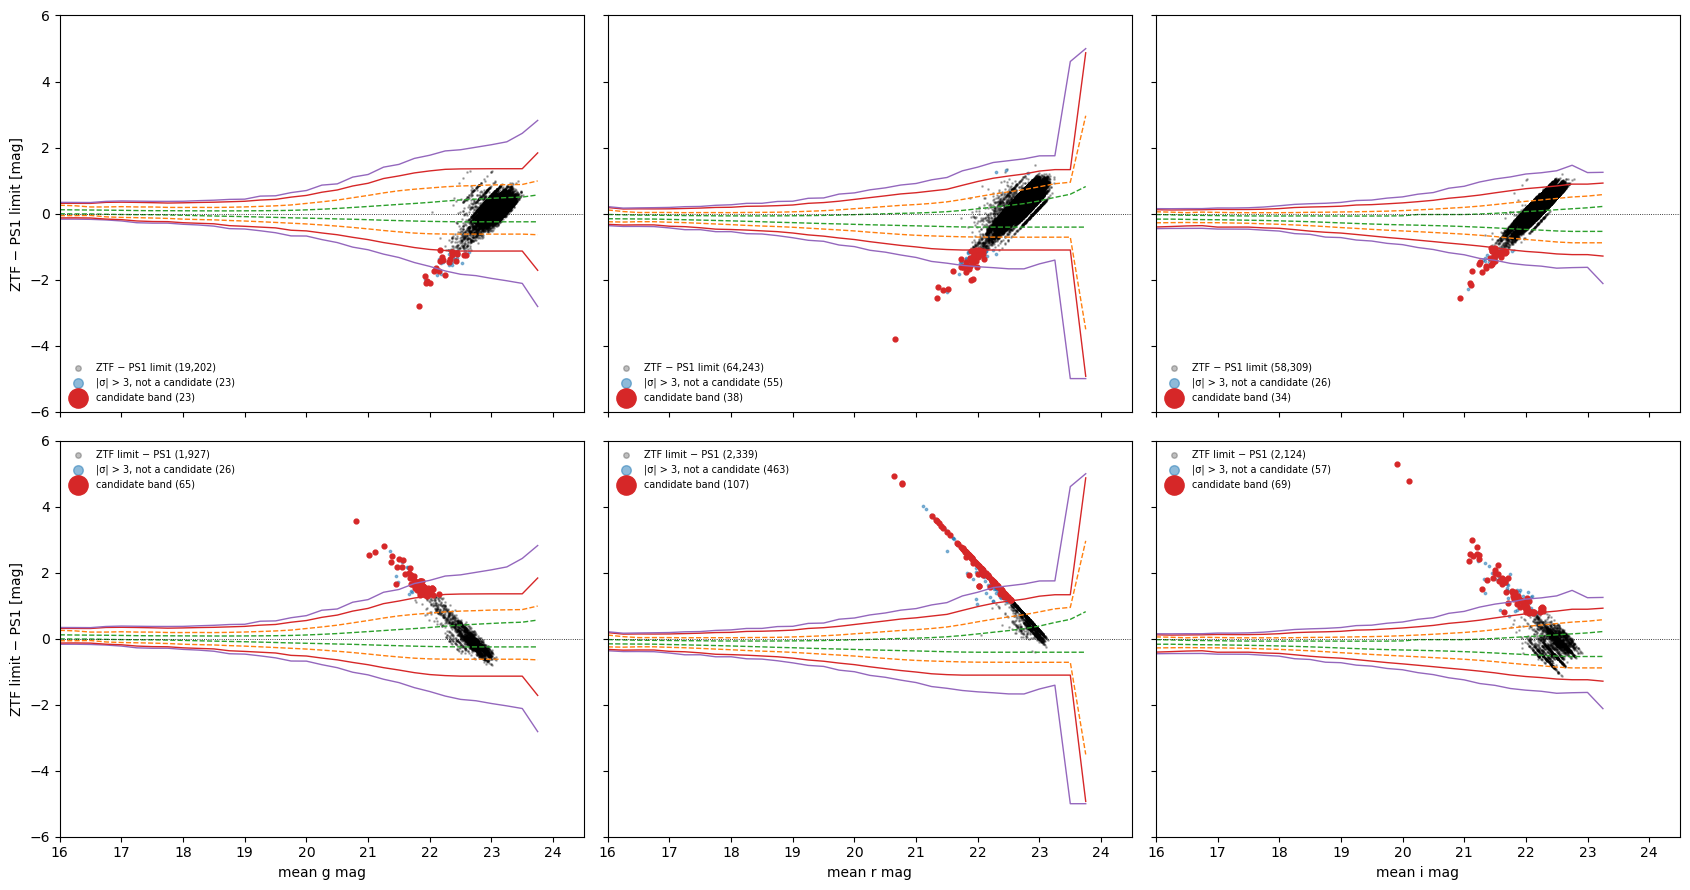

in_both (start 600,397)                                         in_ztf (start 111,105)                                         in_pstarr (start 17,882)             \
                                                 after total fail total fail % unique unique %                  after total fail total fail % unique unique %                    after total fail   
check                                                                                                                                                                                               
|σ| > 3 in >= 2 bands                              384    599,872        99.91      0     0.00                     45    105,315        94.79      0     0.00                      120     15,460   
... >= 2 of them the same sign                     373    599,890        99.92     11     0.00                     45    105,315        94.79      0     0.00                      120     15,460   

                                                             
                               total fail % unique unique %  
check                                                        
|σ| > 3 in >= 2 bands                 86.46      0     0.00  
... >= 2 of them the same sign        86.46      0     0.00

In [ ]:
used = {name: wfs[name].mask(len(wfs[name].steps) - 1) for name in NAMES}
fig, axes = plt.subplots(2, 3, figsize=(17, 9), sharex=True, sharey=True)
for row, (k, what) in enumerate(((1, 'ZTF − PS1 limit'), (2, 'ZTF limit − PS1'))):
    name = ff.CATALOG[k]
    for ax, b in zip(axes[row], 'gri'):
        m = (src[f'{b}_cat'].values == k) & reach[name][b]
        zu, _, pu, _ = ff.compared_magnitudes(src, b); mag = (zu + pu) / 2; d = src[f'{b}_dmag'].values
        big = np.abs(src[f'{b}_sigma'].values) > ff.SIGMA_BOUNDARY
        c = used[name][b]
        ax.scatter(mag[m & ~big], d[m & ~big], s=1, alpha=0.25, color='k', rasterized=True, label=f'{what} ({m.sum():,})')
        ax.scatter(mag[m & big & ~c], d[m & big & ~c], s=3, alpha=0.5, color='C0', rasterized=True, label=f'|σ| > 3, not a candidate ({(m & big & ~c).sum():,})')
        ax.scatter(mag[m & c], d[m & c], s=12, color='C3', label=f'candidate band ({(m & c).sum():,})')
        for n_, col in LEVELS:
            ax.plot(env['point'][b].mag_grid, env['point'][b].get_percentile(env['point'][b].mag_grid, norm.cdf(n_)), color=col, lw=1, ls='-' if abs(n_) >= 3 else '--')
        ax.axhline(0, color='k', lw=0.6, ls=':'); ax.set_xlim(16, 24.5); ax.set_ylim(-6, 6)
        ax.legend(frameon=False, fontsize=7, markerscale=4, loc='lower left' if k == 1 else 'upper left')
        if row == 1: ax.set_xlabel(f'mean {b} mag')
        if b == 'g': ax.set_ylabel(f'{what} [mag]')
plt.tight_layout(); plt.show()
display(catalog_block('interesting'))

In [ ]:
for name in NAMES:
    cutouts_catalog('interesting', name)

saved 2 checks → /Users/adamboesky/Research/long_transients2/Data/fields/000860/review/filter_cutouts/interesting/in_both.png
saved 2 checks → /Users/adamboesky/Research/long_transients2/Data/fields/000860/review/filter_cutouts/interesting/in_ztf.png
saved 2 checks → /Users/adamboesky/Research/long_transients2/Data/fields/000860/review/filter_cutouts/interesting/in_pstarr.png


## 9. Results

- `ff.catalog_flowchart` — the catalogs' checks after the sort (the quality flowcharts are in section 2).
- `ff.significant_bands_table` — candidates by their compared bands with |σ| > 3.
- `ff.annotate_outcomes` — `{b}_dropped_by` and `outcome` for every object.
- `ff.explain` — one object's record from a saved run.

Then the candidates per catalog, and how many old-pipeline AGN / TNS sources are candidates now.

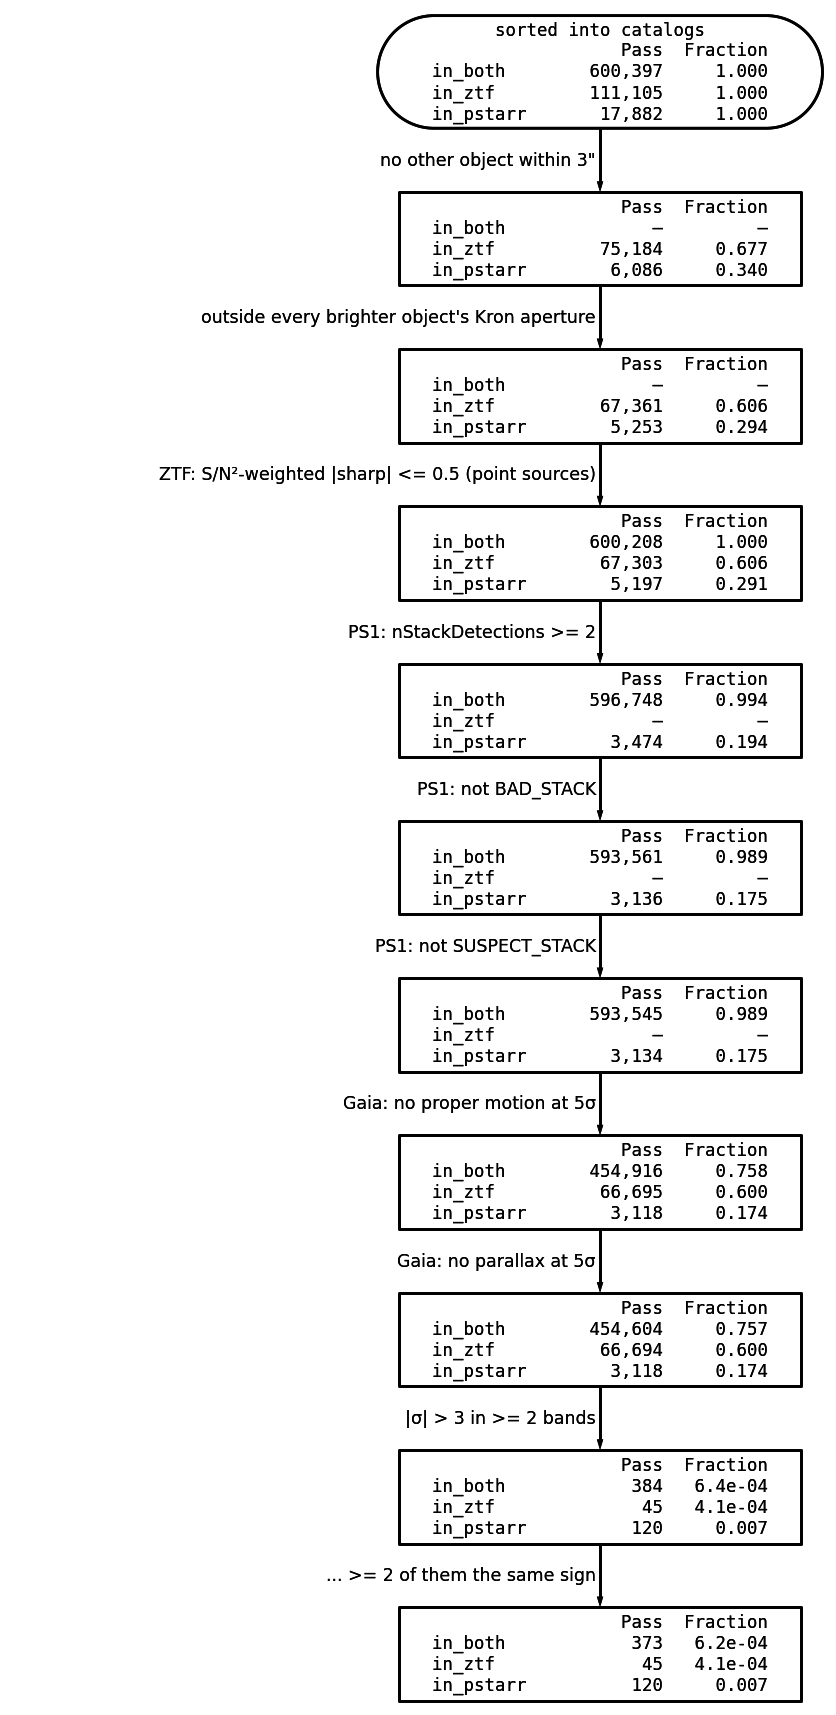

In [ ]:
display(ff.catalog_flowchart(src, CUTS, table=CT))

In [ ]:
display(ff.significant_bands_table(cands))
LT = '/Users/adamboesky/Research/long_transients/Data'
s = pd.read_parquet(f'{LT}/db/sources.parquet', columns=['ra', 'dec', 'fieldid', 'agn_db_matched', 'tns_matched'])
s = s[s.fieldid == FIELD]
cand = pd.concat(cands.values())
for what in ('agn_db_matched', 'tns_matched'):
    k = s[s[what].fillna(False).astype(bool)]
    _, sep, _ = match_coordinates_sky(SkyCoord(k.ra.values * u.deg, k.dec.values * u.deg), SkyCoord(cand.ra.values * u.deg, cand.dec.values * u.deg))
    print(f'{what}: {int((sep.arcsec <= 1.5).sum())} of {len(k)} old-pipeline sources are candidates now')

,in_both,in_ztf,in_pstarr
gri,46,5,1
gr,123,11,51
gi,54,7,13
ri,150,22,55


agn_db_matched: 88 of 148 old-pipeline sources are candidates now
tns_matched: 0 of 4 old-pipeline sources are candidates now


**Every object's record** (`ff.annotate_outcomes`, saved in `objects.parquet`): `outcome` is `candidate`,
`not comparable: <reason>` (never entered a catalog), or `dropped: <step>` (the catalog step at which fewer than two
bands remained). `{b}_dropped_by` is the first step that dropped band b, shared stage included, or `kept`; a band also
counts as dropped at the step where its object fell below two bands. Rows below are in pipeline order.
`ff.explain(FIELD, ra, dec, D)` prints one object's story from the last saved run (`python -m Source_Analysis.filter_field run 860` writes it).

In [ ]:
cat_name = src.catalog.map({**ff.CATALOG, -1: ff.NOT_COMPARABLE}).rename('catalog')
longest = max(NAMES, key=lambda n: len(wfs[n].steps))                  # in_pstarr: every catalog step, in chain order
steps = list(dict.fromkeys(wfs['all'].steps + wfs[longest].steps + [s for name in NAMES for s in wfs[name].steps]))
order = ['candidate'] + [f'not comparable: {r}' for r in ff.REASONS] + [f'dropped: {s}' for s in steps]
t = pd.crosstab(src.outcome.astype(str).rename('outcome'), cat_name)[[*NAMES, ff.NOT_COMPARABLE]]
display(t.reindex([o for o in order if o in t.index] + [o for o in t.index if o not in order]))
db = pd.DataFrame({f'{b} dropped by': src[f'{b}_dropped_by'].astype(str).value_counts() for b in 'gri'})
display(db.reindex([s for s in steps + [ff.KEPT] if s in db.index]).fillna(0).astype(int))

catalog,in_both,in_ztf,in_pstarr,not comparable
outcome,,,,
candidate,373,45,120,0
not comparable: fewer than two measured bands,0,0,0,4517106
not comparable: no comparable band,0,0,0,867467
not comparable: one comparable band,0,0,0,650783
not comparable: one two-sided band,0,0,0,368891
not comparable: mixed one-sided kinds,0,0,0,60901
"dropped: no other object within 3""",0,35921,11796,0
dropped: outside every brighter object's Kron aperture,0,7823,833,0
dropped: ZTF: S/N²-weighted |sharp| <= 0.5 (point sources),189,58,56,0


,g dropped by,r dropped by,i dropped by
>= 2 bands: measured by ZTF or PS1,4723443,4574300,4611479
ZTF: outside bright-star masks,225109,240095,236263
ZTF image covers the position,159884,151883,168340
ZTF: DAOPhot flags = 0,2131,2539,2355
ZTF: > 5 px from a masked pixel,15030,15030,14585
extended: ZTF Kron aperture <= 10% masked,32915,34519,37272
PS1: not in a flagged polar skycell,12898,14118,13579
PS1: residual sky <= 1e-07,6458,27646,16962
PS1: stack nFrames >= 4,44056,39508,16216
PS1: not DEFECT,3075,3626,4994


In [ ]:
# one candidate's record, as ff.explain prints it from a saved run
ex = cands['in_ztf'].index[0] if len(cands['in_ztf']) else cands['in_both'].index[0]
display(src.loc[ex, ff.EXPLAIN_COLS].to_frame().T)

,ra,dec,ztf_idx,ps1_idx,catalog,catalog_reason,outcome,point_source,g_ztf_status,g_ps1_status,g_ztf_psf,g_ps1_psf,g_ztf_snr,g_ps1_snr,g_sigma,g_dropped_by,r_ztf_status,r_ps1_status,r_ztf_psf,r_ps1_psf,r_ztf_snr,r_ps1_snr,r_sigma,r_dropped_by,i_ztf_status,i_ps1_status,i_ztf_psf,i_ps1_psf,i_ztf_snr,i_ps1_snr,i_sigma,i_dropped_by
49564,164.48389,73.645769,49564,-1,1,,candidate,False,D,U,21.866,NaN,7.283555,NaN,-5.356116,kept,U,U,NaN,NaN,NaN,NaN,NaN,>= 2 bands: measured by ZTF or PS1,D,U,20.643,NaN,8.642487,NaN,-5.890587,kept


Highest-|σ| candidates per catalog: ZTF reference (left) and PS1 stack (right) in the band with the largest |σ|
among the bands that make them candidates, 30″. Below: band, mean mag, Δ = ZTF − PS1, σ per band.

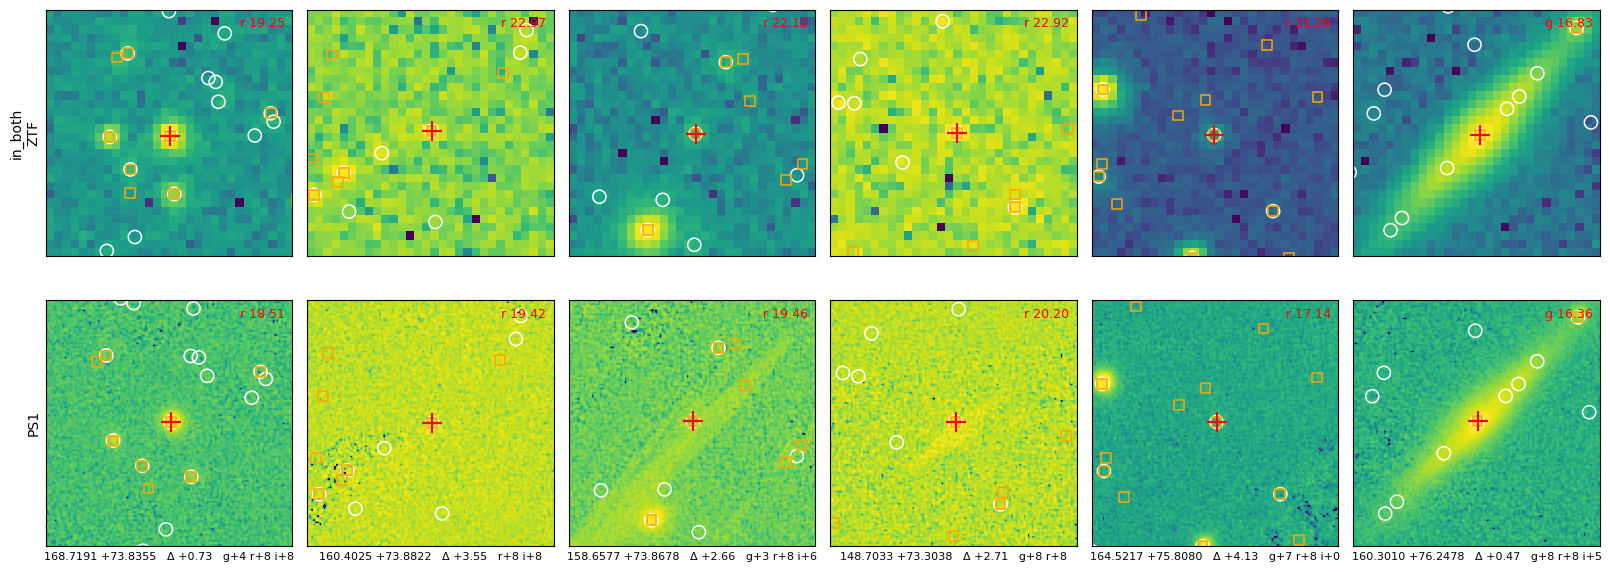

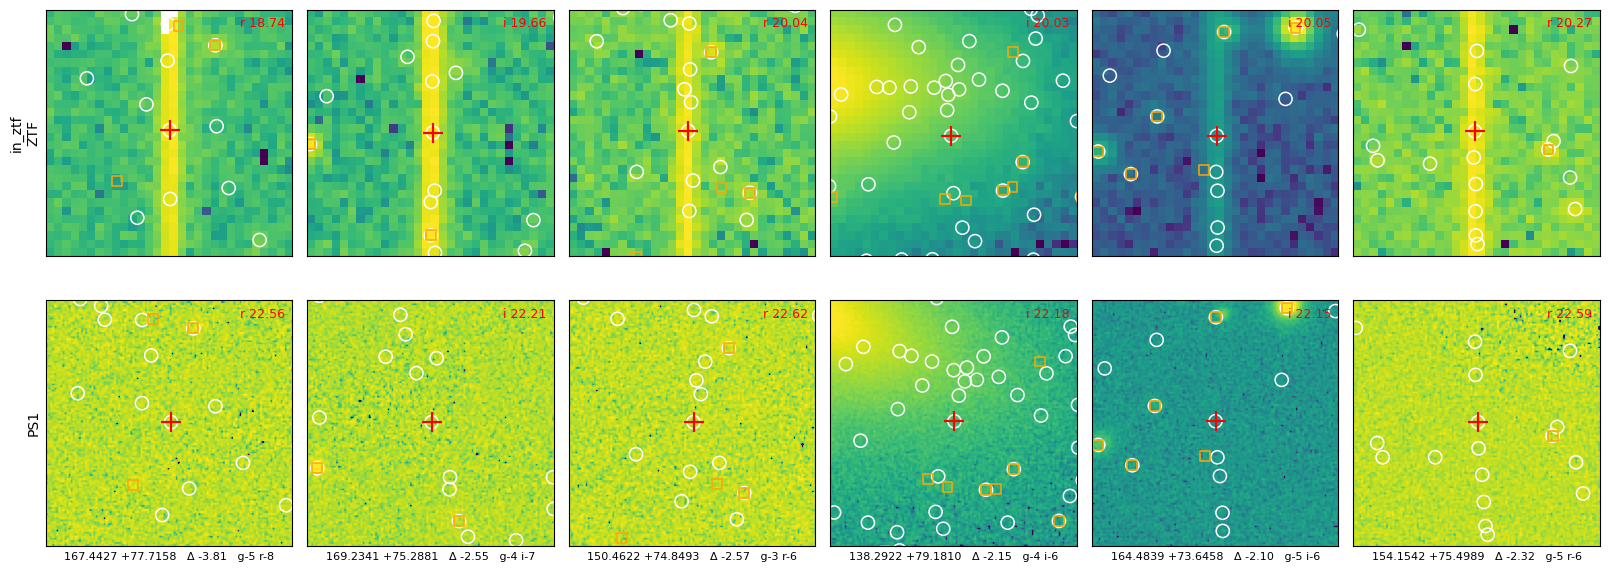

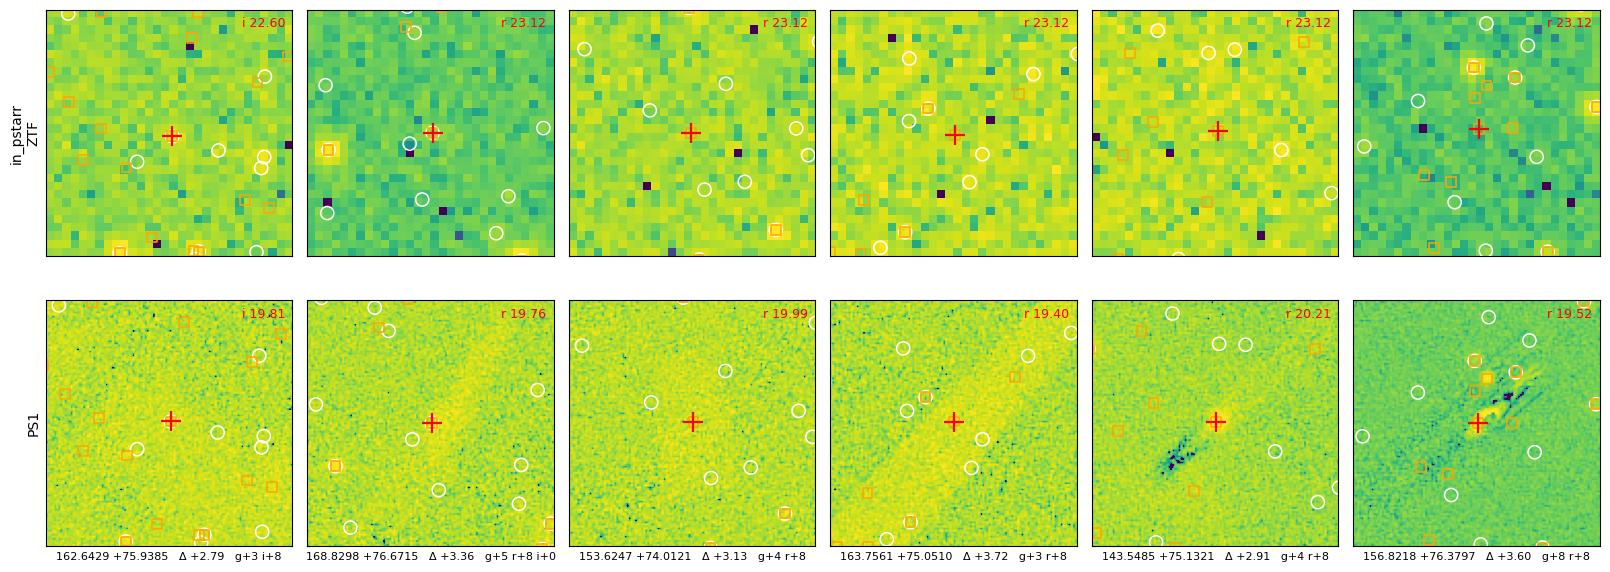

In [ ]:
# highest-|σ| candidates per catalog: ZTF reference over PS1 stack in the band with the largest |σ| among the bands
# that make them candidates; each stamp shows the magnitude actually compared (measurement or limit), the caption Δ and σ
N_SHOW = 6
for name in NAMES:
    cand = cands[name]
    if len(cand) == 0:
        print(f'{name}: no candidates'); continue
    abs_sig = np.column_stack([np.where(used[name][b][cand.index], np.abs(cand[f'{b}_sigma'].values), -1) for b in 'gri'])
    cand = cand.assign(best_band=np.array(list('gri'))[abs_sig.argmax(axis=1)], max_abs_sigma=abs_sig.max(axis=1))
    rows = cand.nlargest(N_SHOW, 'max_abs_sigma')
    files = ps1_filenames(rows[['ra', 'dec']]).round({'ra': 6, 'dec': 6}).groupby(['ra', 'dec', 'filter']).filename.first()
    fig, axes = plt.subplots(2, N_SHOW, figsize=(2.7 * N_SHOW, 6.4), squeeze=False)
    for j, (_, r) in enumerate(rows.iterrows()):
        b = r.best_band
        stamp_pair(axes[0, j], axes[1, j], r, b, files, 30)
        zu, _, pu, _ = (v[0] for v in ff.compared_magnitudes(r.to_frame().T, b))
        for ax, m in ((axes[0, j], zu), (axes[1, j], pu)):      # the compared magnitudes replace the PSF ones
            for t in list(ax.texts):
                if t.get_position() == (0.97, 0.97): t.remove()
            ax.text(0.97, 0.97, f'{b} {m:.2f}', color='red', fontsize=9, ha='right', va='top', transform=ax.transAxes)
        axes[1, j].set_xlabel(f"{r.ra:.4f} {r.dec:+.4f}   Δ {r[f'{b}_dmag']:+.2f}   " + ' '.join(f"{x}{r[f'{x}_sigma']:+.0f}" for x in 'gri' if np.isfinite(r[f'{x}_sigma'])), fontsize=8)
    for j in range(len(rows), N_SHOW): axes[0, j].axis('off'); axes[1, j].axis('off')
    axes[0, 0].set_ylabel(f'{name}\nZTF', fontsize=10); axes[1, 0].set_ylabel('PS1', fontsize=10)
    plt.tight_layout(); plt.show()